# 📓 Catatan Coretan Bimbingan 06: Analisis Distribusi Bobot ($w$)

Dokumen ini mendokumentasikan penjabaran teoretis, analisis komparasi matematis, dan simulasi numerik terkait perbedaan mendasar antara model dengan bobot acak ($w$ berdistribusi Gaussian) vs bobot deterministik ($w$ skalar konstan).

---

## ❓ Pertanyaan:
> **Apakah pembuktian untuk $w$ berdistribusi normal dengan $w$ yang tidak berdistribusi (skalar konstan / deterministik) berbeda?**

---

## 💡 Jawaban Singkat:
**YA, SANGAT BERBEDA SECARA FUNDAMENTAL**, baik dari segi:
1. **Status Matematis Fungsi Laten $f(x)$**:
   - Jika $w$ adalah skalar tetap (deterministik): $f(x) = wx$ **bukan peubah acak**, melainkan nilai pasti.
   - Jika $w \sim \mathcal{N}(0, \sigma_w^2)$: $f(x) = wx$ **adalah peubah acak Gaussian**.
2. **Sumber Keacakan pada $y$**:
   - $w$ deterministik: Satu-satunya sumber keacakan adalah derau pengukuran $\varepsilon \sim \mathcal{N}(0, \sigma_n^2)$.
   - $w$ berdistribusi: Keacakan berasal dari **dua peubah acak independen**, yaitu ketidakpastian model/bobot ($w$) dan derau pengukuran ($\varepsilon$).
3. **MGF dan Distribusi Hasil**:
   - $w$ deterministik: $y \sim \mathcal{N}(wx, \; \sigma_n^2)$ $\implies$ Variansi konstan/homoskedastik (tidak bergantung pada $x$).
   - $w$ berdistribusi: $y \sim \mathcal{N}(0, \; x^2 \sigma_w^2 + \sigma_n^2)$ $\implies$ Variansi bergantung pada masukan $x$ (heteroskedastik).
4. **Korelasi Antar-Titik (Jembatan ke Gaussian Process)**:
   - $w$ deterministik: Observasi pada $x_1$ dan $x_2$ independen, tidak memunculkan fungsi kovariansi/kernel.
   - $w$ berdistribusi: Observasi pada $x_1$ dan $x_2$ berkorelasi melalui $\operatorname{Cov}(f(x_1), f(x_2)) = x_1 x_2 \sigma_w^2$, yang melahirkan **fungsi kernel linier** $k(x_1, x_2)$!

---
## 📐 Penjabaran Matematis Lengkap: Kasus A vs Kasus B

### 1. Kasus A: $w$ Skalar Konstan / Deterministik (Frequentist)
Pada regresi linier klasik, bobot $w \in \mathbb{R}$ adalah parameter tetap yang tidak memiliki ketidakpastian distribusi.
* Model:
  $$y = wx + \varepsilon, \quad \text{dengan } \varepsilon \sim \mathcal{N}(0, \sigma_n^2)$$
* Status $f(x) = wx$: **Konstanta**, bukan variabel acak. MGF dari konstanta:
  $$M_{f(x)}(t) = \mathbb{E}\left[ e^{t (wx)} \right] = e^{t wx}$$
* MGF dari derau $\varepsilon \sim \mathcal{N}(0, \sigma_n^2)$:
  $$M_{\varepsilon}(t) = \mathbb{E}\left[ e^{t \varepsilon} \right] = \exp\left( \frac{1}{2} \sigma_n^2 t^2 \right)$$
* MGF dari observasi $y$:
  $$\begin{aligned}
  M_y(t) &= \mathbb{E}\left[ e^{t (wx + \varepsilon)} \right] = \mathbb{E}\left[ e^{t wx} \cdot e^{t \varepsilon} \right] \\
  &= e^{t wx} \cdot \mathbb{E}\left[ e^{t \varepsilon} \right] \quad (\text{karena } e^{t wx} \text{ adalah konstanta non-acak}) \\
  &= e^{t wx} \cdot \exp\left( \frac{1}{2} \sigma_n^2 t^2 \right) \\
  &= \exp\left( (wx) t + \frac{1}{2} \sigma_n^2 t^2 \right)
  \end{aligned}$$
* **Kesimpulan Kasus A (Teorema Keunikan MGF)**:
  Bentuk ini memiliki parameter $\mu_y = wx$ dan variansi $\sigma_y^2 = \sigma_n^2$. Maka:
  $$\mathbf{y \sim \mathcal{N}\left( wx, \; \sigma_n^2 \right)}$$
  > **Catatan Kunci**: Nilai input $x$ hanya menggeser rata-rata ($\mathbb{E}[y] = wx$), sedangkan variansinya **konstan** ($\operatorname{Var}(y) = \sigma_n^2$) di semua titik $x$.

---

### 2. Kasus B: $w$ Berdistribusi Normal (Bayesian / Weight-Space View)
Pada sudut pandang Bayesian, bobot $w$ diperlakukan sebagai peubah acak dengan distribusi prior Gaussian.
* Model:
  $$f(x) = wx, \quad y = f(x) + \varepsilon, \quad \text{dengan } w \sim \mathcal{N}(0, \sigma_w^2), \quad \varepsilon \sim \mathcal{N}(0, \sigma_n^2), \quad w \perp \varepsilon$$
* Status $f(x) = wx$: **Variabel acak Gaussian**. MGF dari $f(x)$:
  $$\begin{aligned}
  M_{f(x)}(t) &= \mathbb{E}_w\left[ e^{t (wx)} \right] = \mathbb{E}_w\left[ e^{(tx) w} \right] \\
  &= M_w(tx) \quad (\text{karena } w \sim \mathcal{N}(0, \sigma_w^2) \implies M_w(u) = \exp(\tfrac{1}{2} \sigma_w^2 u^2)) \\
  &= \exp\left( \frac{1}{2} \sigma_w^2 (tx)^2 \right) \\
  &= \exp\left( \frac{1}{2} t^2 \left( x^2 \sigma_w^2 \right) \right)
  \end{aligned}$$
  Berdasarkan Teorema Keunikan MGF:
  $$\mathbf{f(x) \sim \mathcal{N}\left( 0, \; x^2 \sigma_w^2 \right)}$$
* MGF dari observasi $y = f(x) + \varepsilon$:
  Karena $w$ dan $\varepsilon$ saling bebas ($w \perp \varepsilon$), maka $f(x)$ dan $\varepsilon$ juga saling bebas. MGF dari penjumlahan dua peubah acak independen adalah hasil kali MGF-nya:
  $$\begin{aligned}
  M_y(t) &= \mathbb{E}_{w, \varepsilon}\left[ e^{t (f(x) + \varepsilon)} \right] \\
  &= \mathbb{E}_w\left[ e^{t f(x)} \right] \cdot \mathbb{E}_\varepsilon\left[ e^{t \varepsilon} \right] \\
  &= M_{f(x)}(t) \cdot M_{\varepsilon}(t) \\
  &= \exp\left( \frac{1}{2} t^2 \left( x^2 \sigma_w^2 \right) \right) \cdot \exp\left( \frac{1}{2} \sigma_n^2 t^2 \right) \\
  &= \exp\left( \frac{1}{2} t^2 \left( x^2 \sigma_w^2 + \sigma_n^2 \right) \right)
  \end{aligned}$$
* **Kesimpulan Kasus B (Teorema Keunikan MGF)**:
  Bentuk ini memiliki parameter $\mu_y = 0$ dan variansi $\sigma_y^2 = x^2 \sigma_w^2 + \sigma_n^2$. Maka:
  $$\mathbf{y \sim \mathcal{N}\left( 0, \; x^2 \sigma_w^2 + \sigma_n^2 \right)}$$
  > **Catatan Kunci**: Variansi total terdiri dari **ketidakpastian epistemik** ($x^2 \sigma_w^2$) yang membesar seiring besarnya $|x|$, ditambah **ketidakpastian aleatorik** derau ($\sigma_n^2$).

---
## 📊 Tabel Perbandingan Komprehensif

| Karakteristik | Kasus A: $w$ Deterministik (Skalar Tetap) | Kasus B: $w$ Probabilistik ($w \sim \mathcal{N}(0, \sigma_w^2)$) |
| :--- | :--- | :--- |
| **Paradigma** | Frequentist / Classical Linear Regression | Bayesian Linear Regression / Weight-Space GP |
| **Sifat Parameter $w$** | Nilai konstan tetap (*fixed true value*) | Variabel acak dengan prior Gaussian |
| **Status $f(x) = wx$** | **Bukan peubah acak** (deterministik) | **Peubah acak Gaussian** |
| **MGF $M_{f(x)}(t)$** | $e^{t(wx)}$ (pergeseran eksponensial linier) | $\exp\left(\frac{1}{2} t^2 (x^2 \sigma_w^2)\right)$ (bentuk kuadratik Gaussian) |
| **Distribusi $f(x)$** | Dirac delta $\delta(f - wx)$ (degenerasi) | $\mathcal{N}(0, \; x^2 \sigma_w^2)$ |
| **Variansi Laten $\operatorname{Var}(f(x))$** | $0$ (pasti, tidak ada ketidakpastian fungsi) | $x^2 \sigma_w^2$ (bergantung jarak $x$ dari titik pusat) |
| **Sumber Keacakan $y$** | Hanya derau $\varepsilon$ | Dua sumber: Bobot $w$ dan Derau $\varepsilon$ |
| **Mekanisme MGF $M_y(t)$** | $e^{twx} \cdot M_\varepsilon(t)$ (faktor konstanta keluar dari ekspektasi) | $M_{f(x)}(t) \cdot M_\varepsilon(t)$ (perkalian MGF dua peubah acak independen) |
| **MGF Observasi $M_y(t)$** | $\exp\left((wx)t + \frac{1}{2}\sigma_n^2 t^2\right)$ | $\exp\left(\frac{1}{2} t^2 (x^2 \sigma_w^2 + \sigma_n^2)\right)$ |
| **Distribusi Observasi $y$** | $\mathcal{N}(wx, \; \sigma_n^2)$ | $\mathcal{N}(0, \; x^2 \sigma_w^2 + \sigma_n^2)$ |
| **Rata-rata $\mathbb{E}[y]$** | $wx$ (bergantung pada input $x$) | $0$ (jika prior mean nol $\mu_w = 0$) |
| **Variansi Total $\operatorname{Var}(y)$** | $\sigma_n^2$ (**konstan / homoskedastik**) | $x^2 \sigma_w^2 + \sigma_n^2$ (**heteroskedastik**) |
| **Jenis Ketidakpastian** | Hanya aleatorik (derau data) | Epistemik ($x^2 \sigma_w^2$) + Aleatorik ($\sigma_n^2$) |
| **Kovariansi Antar Titik** | $\operatorname{Cov}(f(x_1), f(x_2)) = 0$ | $\operatorname{Cov}(f(x_1), f(x_2)) = x_1 x_2 \sigma_w^2$ |
| **Kemunculan Kernel** | **Tidak ada fungsi kernel** | **Melahirkan Kernel Linier** $k(x_1, x_2) = x_1 x_2 \sigma_w^2$ |
| **Jembatan ke GP** | Tidak dapat ditransisikan ke GP | Fondasi transisi *Weight-Space* ke *Function-Space* |

In [1]:
import numpy as np
import pandas as pd

# =========================================================================
# SIMULASI MONTE CARLO: VERIFIKASI MGF EMPIRIS VS TEORITIS
# =========================================================================

# Parameter simulasi
np.random.seed(42)
N_samples = 500_000
x_val = 2.0        # Titik input yang diuji
sigma_n = 0.5      # Standar deviasi noise
w_fixed = 1.5      # Skalar deterministik untuk Kasus A
sigma_w = 1.0      # Standar deviasi bobot acak untuk Kasus B

# Nilai parameter uji MGF (t)
t_values = np.array([-0.3, -0.15, 0.0, 0.15, 0.3])

# 1. Sampel Kasus A: w deterministik
eps_A = np.random.normal(0, sigma_n, size=N_samples)
y_A = w_fixed * x_val + eps_A

# 2. Sampel Kasus B: w Gaussian acak
w_samples = np.random.normal(0, sigma_w, size=N_samples)
eps_B = np.random.normal(0, sigma_n, size=N_samples)
y_B = w_samples * x_val + eps_B

# Evaluasi MGF Empiris vs MGF Teoritis
results = []
for t in t_values:
    # Kasus A: w deterministik
    mgf_emp_A = np.mean(np.exp(t * y_A))
    mgf_theo_A = np.exp((w_fixed * x_val) * t + 0.5 * (sigma_n**2) * (t**2))
    
    # Kasus B: w Gaussian acak
    mgf_emp_B = np.mean(np.exp(t * y_B))
    var_B_theo = (x_val**2) * (sigma_w**2) + (sigma_n**2)
    mgf_theo_B = np.exp(0.5 * var_B_theo * (t**2))
    
    results.append({
        "t": t,
        "Kasus A (Empiris)": mgf_emp_A,
        "Kasus A (Teoritis)": mgf_theo_A,
        "Selisih A": abs(mgf_emp_A - mgf_theo_A),
        "Kasus B (Empiris)": mgf_emp_B,
        "Kasus B (Teoritis)": mgf_theo_B,
        "Selisih B": abs(mgf_emp_B - mgf_theo_B),
    })

df_results = pd.DataFrame(results)
print("--- HASIL VERIFIKASI MGF MONTE CARLO ---")
print(df_results.to_string(index=False))

--- HASIL VERIFIKASI MGF MONTE CARLO ---
    t  Kasus A (Empiris)  Kasus A (Teoritis)  Selisih A  Kasus B (Empiris)  Kasus B (Teoritis)  Selisih B
-0.30           0.411246            0.411169   0.000077           1.212186            1.210762   0.001423
-0.15           0.639482            0.639424   0.000058           1.049667            1.048974   0.000693
 0.00           1.000000            1.000000   0.000000           1.000000            1.000000   0.000000
 0.15           1.572596            1.572729   0.000134           1.048183            1.048974   0.000791
 0.30           2.487017            2.487430   0.000413           1.208817            1.210762   0.001945


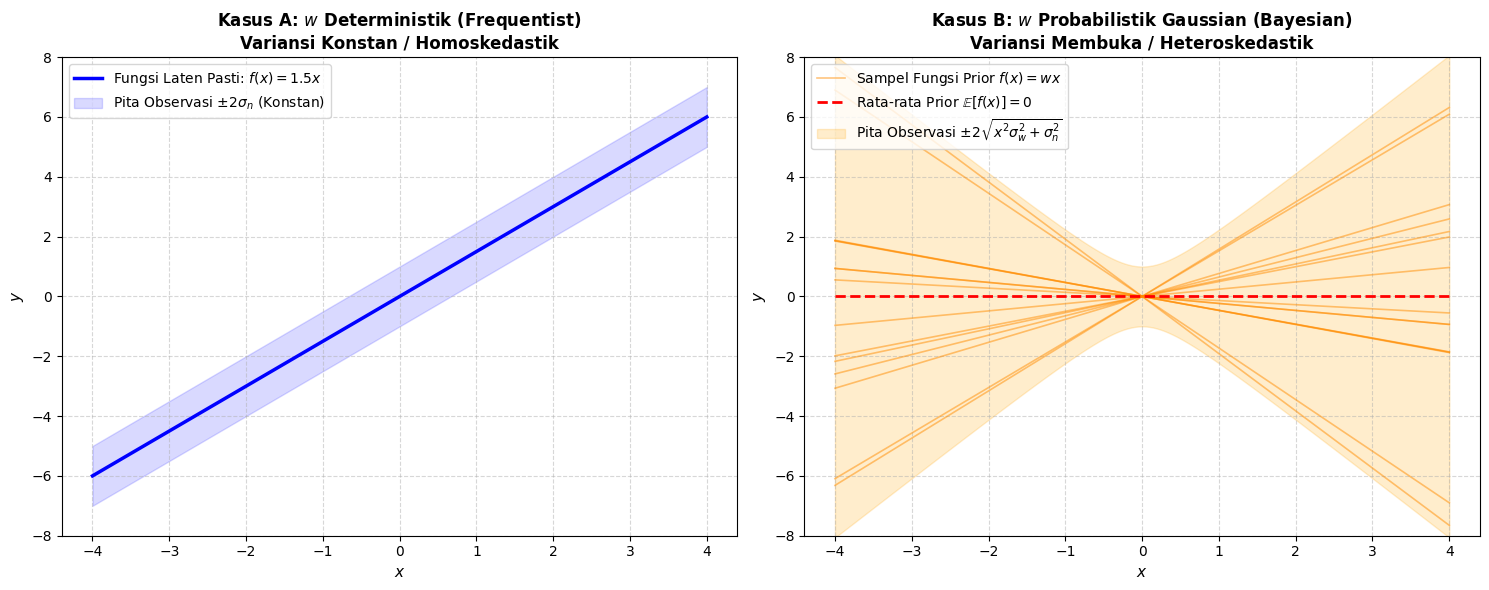

In [2]:
import matplotlib.pyplot as plt

# =========================================================================
# VISUALISASI KOMPARASI: W DETERMINISTIK VS W GAUSSIAN ACAK
# =========================================================================

x_grid = np.linspace(-4, 4, 200)

# 1. Kasus A: w deterministik (w = 1.5, sigma_n = 0.5)
f_A = w_fixed * x_grid
var_y_A = np.full_like(x_grid, sigma_n**2)
std_y_A = np.sqrt(var_y_A)

# 2. Kasus B: w Gaussian acak (w ~ N(0, 1), sigma_n = 0.5)
# Rata-rata fungsi adalah 0
f_B_mean = np.zeros_like(x_grid)
var_f_B = (x_grid**2) * (sigma_w**2)
var_y_B = var_f_B + (sigma_n**2)
std_y_B = np.sqrt(var_y_B)

# Sampling 15 garis fungsi acak untuk Kasus B
np.random.seed(42)
w_draws = np.random.normal(0, sigma_w, size=15)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: Kasus A
axes[0].plot(x_grid, f_A, 'b-', lw=2.5, label=f'Fungsi Laten Pasti: $f(x) = {w_fixed}x$')
axes[0].fill_between(x_grid, f_A - 2*std_y_A, f_A + 2*std_y_A, color='blue', alpha=0.15, 
                     label=r'Pita Observasi $\pm 2\sigma_n$ (Konstan)')
axes[0].set_title('Kasus A: $w$ Deterministik (Frequentist)\nVariansi Konstan / Homoskedastik', fontsize=12, fontweight='bold')
axes[0].set_xlabel('$x$', fontsize=11)
axes[0].set_ylabel('$y$', fontsize=11)
axes[0].set_ylim(-8, 8)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper left', fontsize=10)

# Panel 2: Kasus B
for i, w_sample in enumerate(w_draws):
    axes[1].plot(x_grid, w_sample * x_grid, color='darkorange', alpha=0.5, lw=1.2, 
                 label='Sampel Fungsi Prior $f(x) = wx$' if i == 0 else "")
axes[1].plot(x_grid, f_B_mean, 'r--', lw=2.0, label=r'Rata-rata Prior $\mathbb{E}[f(x)] = 0$')
axes[1].fill_between(x_grid, f_B_mean - 2*std_y_B, f_B_mean + 2*std_y_B, color='orange', alpha=0.2, 
                     label=r'Pita Observasi $\pm 2\sqrt{x^2\sigma_w^2 + \sigma_n^2}$')
axes[1].set_title('Kasus B: $w$ Probabilistik Gaussian (Bayesian)\nVariansi Membuka / Heteroskedastik', fontsize=12, fontweight='bold')
axes[1].set_xlabel('$x$', fontsize=11)
axes[1].set_ylabel('$y$', fontsize=11)
axes[1].set_ylim(-8, 8)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

---
## 🎯 Refleksi Konseptual: Mengapa Dosen Pembimbing Menanyakan Hal Ini?

1. **Jembatan dari Ruang Bobot (*Weight-Space View*) ke Ruang Fungsi (*Function-Space View*)**:
   * Jika $w$ diasumsikan deterministik (regresi linier klasik), kita **tidak akan pernah sampai ke konsep Gaussian Process**, karena nilai fungsi laten $f(x)$ tidak memiliki distribusi probabilitas dan tidak memiliki korelasi antar-titik:
     $$\operatorname{Cov}(f(x_1), f(x_2)) = 0$$
   * Namun, begitu kita memandang $w$ sebagai peubah acak Gaussian $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \Sigma_p)$, kumpulan sembarang titik fungsi $[\, f(\mathbf{x}_1), \dots, f(\mathbf{x}_n) \,]^T$ otomatis berdistribusi normal multivariat:
     $$\mathbf{f} \sim \mathcal{N}\left( \mathbf{0}, \; X \Sigma_p X^T \right)$$
   * Elemen matriks kovariansi $[K]_{ij} = \mathbf{x}_i^T \Sigma_p \mathbf{x}_j$ inilah yang secara langsung bertransisi menjadi **fungsi kernel** $k(\mathbf{x}_i, \mathbf{x}_j)$ ketika masukan dipetakan ke ruang fitur berdimensi tinggi atau tak-hingga $\boldsymbol{\phi}(\mathbf{x})$.

2. **Dekomposisi Ketidakpastian (Epistemik vs Aleatorik)**:
   * **Ketidakpastian Aleatorik** ($\sigma_n^2$): Derau inheren pengukuran data yang tidak dapat dihilangkan.
   * **Ketidakpastian Epistemik** ($x^2 \sigma_w^2$ atau $\mathbf{x}^T \Sigma_p \mathbf{x}$): Ketidaktahuan model terhadap fungsi sebenarnya. Pada GP, komponen inilah yang menciut ketika ada data observasi (pada posterior) dan membesar di area yang belum pernah diobservasi (*uncertainty quantification*).

3. **Kesimpulan Akhir**:
   Pembuktian untuk $w$ acak vs $w$ deterministik **sangat berbeda secara fundamental**:
   * Pada $w$ deterministik, pembuktian MGF hanya menggeser rata-rata normalitas dari derau $\varepsilon$.
   * Pada $w$ acak Gaussian, pembuktian MGF adalah konvolusi analitik dari dua variabel acak Gaussian independen yang melahirkan struktur kovariansi fungsi laten $K = X \Sigma_p X^T$.

---
# 🔍 Analisis Komparasi Mendalam: Formula di PDF Kredit vs Persamaan (2.3) Buku GPML (Rasmussen & Williams, 2006)

Bagian ini secara khusus menjawab pertanyaan:
> **"Apa perbedaan antara yang kita tulis di PDF kredit bimbingan dengan Persamaan (2.3) pada buku Gaussian Processes for Machine Learning (GPML) oleh Rasmussen & Williams?"**

---

## 1. Bunyi Persamaan (2.3) pada Buku Rasmussen & Williams (hlm. 9)
Pada Bab 2.1.1 (*The Standard Linear Model*), Rasmussen & Williams mendefinisikan observasi target dengan galat Gaussian independen $\varepsilon_i \sim \mathcal{N}(0, \sigma_n^2)$:
$$\begin{aligned}
p(\mathbf{y} \mid X, \mathbf{w}) &= \prod_{i=1}^n p(y_i \mid \mathbf{x}_i, \mathbf{w}) = \prod_{i=1}^n \frac{1}{\sqrt{2\pi}\sigma_n} \exp\left( -\frac{(y_i - \mathbf{x}_i^\top \mathbf{w})^2}{2\sigma_n^2} \right) \\
&= \frac{1}{(2\pi \sigma_n^2)^{n/2}} \exp\left( -\frac{1}{2\sigma_n^2} |\mathbf{y} - X^\top \mathbf{w}|^2 \right) \\
&= \mathcal{N}\left( X^\top \mathbf{w}, \; \sigma_n^2 I \right)
\end{aligned} \quad \text{--- [Persamaan (2.3) Rasmussen]}$$

Persamaan (2.3) ini secara tegas adalah **LIKELIHOOD** (fungsi kemungkinan bersyarat dari data observasi $\mathbf{y}$ **jika vektor bobot $\mathbf{w}$ diketahui / dikondisikan**).

---

## 2. Apa yang Kita Tuliskan di PDF Kredit Bimbingan 06?
Di dokumen bimbingan kita, kita membagi pembuktian ke dalam **dua kasus**:
1. **Kasus 1 ($w \in \mathbb{R}$ skalar konstan)**:
   $$y \sim \mathcal{N}\left( wx, \; \sigma_n^2 \right)$$
2. **Kasus 2 ($w \sim \mathcal{N}(0, \sigma_w^2)$ berdistribusi normal, $w$ dan $\varepsilon$ saling bebas)**:
   $$y \sim \mathcal{N}\left( 0, \; x^2 \sigma_w^2 + \sigma_n^2 \right)$$
   dan dalam bentuk vektor multivariat:
   $$\mathbf{y} \sim \mathcal{N}\left( \mathbf{0}, \; X \Sigma_p X^\top + \sigma_n^2 I_n \right)$$

---

## 3. Empat Perbedaan Fundamental Antara PDF Kredit vs Persamaan (2.3) Rasmussen

### A. Perbedaan Status Probabilitas: *Likelihood* vs *Marginal Distribution*
* **Persamaan (2.3) Rasmussen adalah LIKELIHOOD bersyarat**: $p(\mathbf{y} \mid X, \mathbf{w})$. 
  - Probabilitas ini mengasumsikan $\mathbf{w}$ **telah diketahui dan tetap** (*given/fixed*).
  - Pertanyaan yang dijawab: *"Jika kita sudah memegang bobot tertentu $\mathbf{w}$, berapa peluang kita mengamati data $\mathbf{y}$?"*
* **Kasus 2 pada PDF Kredit adalah MARGINAL (Prior Predictive Distribution)**: $p(\mathbf{y} \mid X)$.
  - Probabilitas ini memandang $\mathbf{w}$ **tidak diketahui**, melainkan variabel acak yang **diintegralkan keluar (*marginalized out*)** terhadap seluruh kemungkinan prior $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \Sigma_p)$.
  - Pertanyaan yang dijawab: *"Sebelum kita mengamati data apa pun, bagaimana sebaran gabungan data $\mathbf{y}$ di bawah ketidakpastian prior bobot $\mathbf{w}$ dan galat $\varepsilon$?"*

### B. Hubungan Antara Kasus 1 PDF Kredit dengan Persamaan (2.3) Rasmussen
* Formula **Kasus 1** di PDF kita ($y \sim \mathcal{N}(wx, \sigma_n^2)$) sesungguhnya **identik secara matematis dengan Persamaan (2.3) Rasmussen untuk versi 1 data point ($n=1$) dan 1 dimensi ($d=1$)**.
* Ketika $w$ dipandang sebagai konstanta yang nilainya diberikan, maka sebaran $y$ berpusat pada $wx$ dan variansinya murni galat $\sigma_n^2$.

### C. Sumber Ketidakpastian dan Matriks Kovariansi (Kemunculan Kernel)
* **Pada Persamaan (2.3) Rasmussen**:
  $$\operatorname{Cov}(\mathbf{y} \mid X, \mathbf{w}) = \sigma_n^2 I$$
  - Kovariansi antar dua titik berbeda adalah **nol** (bersifat *conditionally independent*): data di $x_1$ tidak memberikan informasi mengenai data di $x_2$ jika $w$ sudah diketahui.
  - Persamaan (2.3) saja **belum melahirkan Gaussian Process**, karena matriks kovariansinya hanya diagonal (tidak ada relasi kernel).
* **Pada Kasus 2 PDF Kredit**:
  $$\operatorname{Cov}(\mathbf{y} \mid X) = X \Sigma_p X^\top + \sigma_n^2 I_n$$
  - Kovariansi antar dua titik berbeda **tidak nol**: $\operatorname{Cov}(y_i, y_j) = \mathbf{x}_i^\top \Sigma_p \mathbf{x}_j$.
  - Struktur kuadratik $X \Sigma_p X^\top$ inilah **cikal bakal fungsi kernel** $k(\mathbf{x}_i, \mathbf{x}_j) = \mathbf{x}_i^\top \Sigma_p \mathbf{x}_j$ yang menjadi fondasi transformasi ke **Gaussian Process**!

### D. Di Mana Letak Formula Kasus 2 PDF Kredit di Buku Rasmussen?
* Di buku GPML Rasmussen, formula Kasus 2 kita berada di **Persamaan (2.6) dan (2.11)** (hlm. 9 dan hlm. 12):
  $$p(\mathbf{y} \mid X) = \int p(\mathbf{y} \mid X, \mathbf{w}) \, p(\mathbf{w}) \, d\mathbf{w} = \mathcal{N}\left(\mathbf{0}, \; X^\top \Sigma_p X + \sigma_n^2 I\right)$$
* **Perbedaan Metode Penurunan**:
  - **Rasmussen**: Menyelesaikan integral konvolusi Gaussian multivariat $\int \mathcal{N}(X^\top \mathbf{w}, \sigma_n^2 I) \mathcal{N}(\mathbf{0}, \Sigma_p) d\mathbf{w}$ dengan melengkapi kuadrat (*completing the square*).
  - **PDF Kredit Kita**: Menurunkan secara sangat efisien dan elegan menggunakan sifat **Moment Generating Function (MGF)**: $M_{\mathbf{y}}(\mathbf{t}) = M_{\mathbf{f}}(\mathbf{t}) \cdot M_{\boldsymbol{\varepsilon}}(\mathbf{t})$.

---

## 4. Tabel Matriks Komparasi Ringkas

| Aspek Pembeda | Persamaan (2.3) Rasmussen (GPML) | Kasus 1 PDF Kredit | Kasus 2 PDF Kredit |
| :--- | :--- | :--- | :--- |
| **Nama Probabilitas** | **Likelihood** $p(\mathbf{y} \mid X, \mathbf{w})$ | Distribusi $y$ untuk skalar konstan | **Marginal / Prior Predictive** $p(\mathbf{y} \mid X)$ |
| **Perlakuan Parameter $\mathbf{w}$** | **Dikondisikan** (*given/fixed*) | Nilai skalar konstan | **Diintegralkan keluar** (acak $\sim \mathcal{N}(\mathbf{0},\Sigma_p)$) |
| **Rata-rata (Mean $\boldsymbol{\mu}$)** | $X^\top \mathbf{w}$ (mengikuti nilai $\mathbf{w}$) | $wx$ | $\mathbf{0}$ (asumsi prior berpusat di nol) |
| **Kovariansi / Variansi** | $\sigma_n^2 I$ (murni galat) | $\sigma_n^2$ (homoskedastik) | $X\Sigma_p X^\top + \sigma_n^2 I$ (heteroskedastik) |
| **Korelasi Antar Titik** | $\operatorname{Cov}(y_i, y_j) = 0$ ($i \neq j$) | $0$ | $\mathbf{x}_i^\top \Sigma_p \mathbf{x}_j$ (saling berkorelasi) |
| **Fungsi Kernel** | Belum ada | Belum ada | **Melahirkan Kernel Linier** $k(\mathbf{x}_i, \mathbf{x}_j)$ |
| **Persamaan Ekuivalen di GPML** | Eq. (2.3) | Eq. (2.3) versi univariat ($n=1, d=1$) | **Eq. (2.6) & Eq. (2.11)** (hlm. 9 & 12) |
| **Teknik Pembuktian** | Perkalian densitas Gaussian i.i.d. | Aljabar ekspektasi MGF | Perkalian MGF dua peubah acak bebas |

<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:47: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:47: SyntaxWarning: invalid escape sequence '\m'
C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_27464\3297047444.py:33: SyntaxWarning: invalid escape sequence '\m'
  axes[0].set_title('Persamaan (2.3) GPML Rasmussen:\n$p(y \mid X, w) = \mathcal{N}(X^\top w, \sigma_n^2 I)$ [LIKELIHOOD]', fontsize=11, fontweight='bold')
C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_27464\3297047444.py:43: SyntaxWarning: invalid escape sequence '\s'
  label='Sampel fungsi $w x$ dengan $w \sim \mathcal{N}(0, \sigma_w^2)$' if i == 0 else "")
C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_27464\3297047444.py:44: SyntaxWarning: invalid

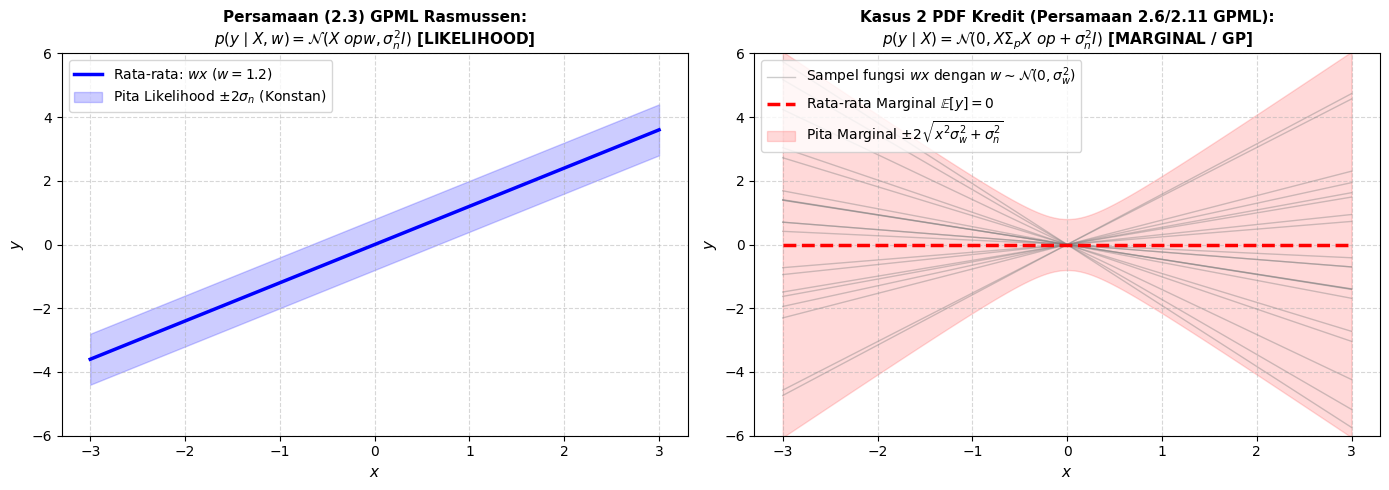

Kesimpulan Simulasi:
1. Likelihood (Eq 2.3): Standar deviasi di x = 0 adalah 0.40, di x = 2 adalah 0.40 (SAMA)
2. Marginal (Kasus 2): Standar deviasi di x = 0 adalah 0.40, di x = 2 adalah 2.04 (MEMBESAR KARENA KETIDAKPASTIAN MODEL)


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================================================
# SIMULASI & VISUALISASI PERBEDAAN:
# PERSAMAAN (2.3) RASMUSSEN (LIKELIHOOD) VS KASUS 2 PDF KREDIT (MARGINAL)
# =========================================================================

np.random.seed(42)
x_test = np.linspace(-3, 3, 200)
sigma_n = 0.4   # Standar deviasi galat
sigma_w = 1.0   # Standar deviasi prior bobot

# 1. Model Persamaan (2.3) Rasmussen: Likelihood p(y | x, w) dengan w TERKONDISI (misal w = 1.2)
w_conditioned = 1.2
mu_likelihood = w_conditioned * x_test
std_likelihood = np.full_like(x_test, sigma_n)

# 2. Model Kasus 2 PDF Kredit: Marginal Likelihood p(y | x) dengan w DIINTEGRALKAN KELUAR
mu_marginal = np.zeros_like(x_test)
var_marginal = (x_test**2) * (sigma_w**2) + (sigma_n**2)
std_marginal = np.sqrt(var_marginal)

# Sampling garis dari prior p(w) untuk mendemonstrasikan asal-usul Marginal
w_samples = np.random.normal(0, sigma_w, size=20)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Persamaan (2.3) Rasmussen (Likelihood p(y | x, w))
axes[0].plot(x_test, mu_likelihood, 'b-', lw=2.5, label=f'Rata-rata: $w x$ ($w={w_conditioned}$)')
axes[0].fill_between(x_test, mu_likelihood - 2*std_likelihood, mu_likelihood + 2*std_likelihood,
                     color='blue', alpha=0.2, label=r'Pita Likelihood $\pm 2\sigma_n$ (Konstan)')
axes[0].set_title('Persamaan (2.3) GPML Rasmussen:\n$p(y \mid X, w) = \mathcal{N}(X^\top w, \sigma_n^2 I)$ [LIKELIHOOD]', fontsize=11, fontweight='bold')
axes[0].set_xlabel('$x$', fontsize=11)
axes[0].set_ylabel('$y$', fontsize=11)
axes[0].set_ylim(-6, 6)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper left', fontsize=10)

# Panel 2: Kasus 2 PDF Kredit (Marginal p(y | x) = ∫ p(y|x,w)p(w)dw)
for i, w_s in enumerate(w_samples):
    axes[1].plot(x_test, w_s * x_test, color='gray', alpha=0.4, lw=1.0,
                 label='Sampel fungsi $w x$ dengan $w \sim \mathcal{N}(0, \sigma_w^2)$' if i == 0 else "")
axes[1].plot(x_test, mu_marginal, 'r--', lw=2.5, label='Rata-rata Marginal $\mathbb{E}[y] = 0$')
axes[1].fill_between(x_test, mu_marginal - 2*std_marginal, mu_marginal + 2*std_marginal,
                     color='red', alpha=0.15, label=r'Pita Marginal $\pm 2\sqrt{x^2\sigma_w^2 + \sigma_n^2}$')
axes[1].set_title('Kasus 2 PDF Kredit (Persamaan 2.6/2.11 GPML):\n$p(y \mid X) = \mathcal{N}(0, X \Sigma_p X^\top + \sigma_n^2 I)$ [MARGINAL / GP]', fontsize=11, fontweight='bold')
axes[1].set_xlabel('$x$', fontsize=11)
axes[1].set_ylabel('$y$', fontsize=11)
axes[1].set_ylim(-6, 6)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

print("Kesimpulan Simulasi:")
print(f"1. Likelihood (Eq 2.3): Standar deviasi di x = 0 adalah {std_likelihood[100]:.2f}, di x = 2 adalah {std_likelihood[166]:.2f} (SAMA)")
print(f"2. Marginal (Kasus 2): Standar deviasi di x = 0 adalah {std_marginal[100]:.2f}, di x = 2 adalah {std_marginal[166]:.2f} (MEMBESAR KARENA KETIDAKPASTIAN MODEL)")


---
# 🔬 Pembuktian Eksak Likelihood Persamaan (2.3) GPML Rasmussen Menggunakan MGF

## ❓ Pertanyaan:
> **"Apakah likelihood pada Persamaan (2.3) buku GPML Rasmussen bisa ditunjukkan menggunakan Moment Generating Function (MGF)?"**

---

## 💡 Jawaban: YA, SANGAT BISA!
Likelihood pada Persamaan (2.3) dapat diturunkan secara langsung dan eksak menggunakan **Conditional Moment Generating Function** (MGF bersyarat).

---

## 1. Formulasi Model Observasi
Pada Bab 2.1.1 buku Rasmussen & Williams (2006, hlm. 8--9), model observasi multivariat untuk $n$ titik data dengan dimensi input $d$ dituliskan sebagai:
$$\mathbf{y} = X^\top \mathbf{w} + \boldsymbol{\varepsilon}$$
di mana:
* $X = [\mathbf{x}_1, \dots, \mathbf{x}_n] \in \mathbb{R}^{d \times n}$ adalah matriks desain masukan.
* $\mathbf{w} \in \mathbb{R}^d$ adalah vektor bobot yang **dikondisikan / bernilai tetap** (*given/conditioned parameter*).
* $\boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma_n^2 I_n)$ adalah vektor galat acak Gaussian independen berdimensi $n$.

---

## 2. Definisi MGF Bersyarat (*Conditional MGF*)
MGF dari vektor observasi $\mathbf{y}$ bersyarat pada input $X$ dan bobot $\mathbf{w}$ didefinisikan sebagai:
$$M_{\mathbf{y} \mid X, \mathbf{w}}(\mathbf{t}) \triangleq \mathbb{E}\left[ \exp\left( \mathbf{t}^\top \mathbf{y} \right) \;\middle|\; X, \mathbf{w} \right], \quad \forall \mathbf{t} \in \mathbb{R}^n$$

---

## 3. Langkah Penurunan Aljabar MGF

Substitusikan model observasi $\mathbf{y} = X^\top \mathbf{w} + \boldsymbol{\varepsilon}$ ke dalam ekspektasi:
$$\begin{aligned}
M_{\mathbf{y} \mid X, \mathbf{w}}(\mathbf{t}) &= \mathbb{E}\left[ \exp\left( \mathbf{t}^\top (X^\top \mathbf{w} + \boldsymbol{\varepsilon}) \right) \;\middle|\; X, \mathbf{w} \right] \\
&= \mathbb{E}\left[ \exp\left( \mathbf{t}^\top X^\top \mathbf{w} + \mathbf{t}^\top \boldsymbol{\varepsilon} \right) \;\middle|\; X, \mathbf{w} \right] \\
&= \mathbb{E}\left[ \exp\left( \mathbf{t}^\top X^\top \mathbf{w} \right) \cdot \exp\left( \mathbf{t}^\top \boldsymbol{\varepsilon} \right) \;\middle|\; X, \mathbf{w} \right]
\end{aligned}$$

### Mengeluarkan Suku Deterministik:
Karena kondisi $X$ dan $\mathbf{w}$ **diberikan (diketahui nilainya)**, maka perkalian skalar $\mathbf{t}^\top X^\top \mathbf{w}$ adalah **konstanta non-acak**. Berdasarkan sifat kelinieran ekspektasi, faktor $\exp(\mathbf{t}^\top X^\top \mathbf{w})$ dapat dikeluarkan dari operator ekspektasi:
$$M_{\mathbf{y} \mid X, \mathbf{w}}(\mathbf{t}) = \exp\left( \mathbf{t}^\top X^\top \mathbf{w} \right) \cdot \mathbb{E}\left[ \exp\left( \mathbf{t}^\top \boldsymbol{\varepsilon} \right) \right]$$

### Substitusi MGF Galat Gaussian Multivariat:
Perhatikan bahwa $\mathbb{E}\left[ \exp(\mathbf{t}^\top \boldsymbol{\varepsilon}) \right]$ adalah MGF dari vektor galat $\boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma_n^2 I_n)$:
$$M_{\boldsymbol{\varepsilon}}(\mathbf{t}) = \exp\left( \frac{1}{2} \mathbf{t}^\top (\sigma_n^2 I_n) \mathbf{t} \right) = \exp\left( \frac{1}{2} \sigma_n^2 \|\mathbf{t}\|^2 \right)$$

Dengan mengalikan kedua suku, diperoleh:
$$\begin{aligned}
M_{\mathbf{y} \mid X, \mathbf{w}}(\mathbf{t}) &= \exp\left( \mathbf{t}^\top (X^\top \mathbf{w}) \right) \cdot \exp\left( \frac{1}{2} \mathbf{t}^\top (\sigma_n^2 I_n) \mathbf{t} \right) \\
&= \exp\left( \mathbf{t}^\top (X^\top \mathbf{w}) + \frac{1}{2} \mathbf{t}^\top (\sigma_n^2 I_n) \mathbf{t} \right)
\end{aligned}$$

---

## 4. Pencocokan Parameter & Kesimpulan Teorema Keunikan MGF

Bandingkan hasil di atas dengan bentuk umum MGF distribusi normal multivariat $\mathbf{Z} \sim \mathcal{N}(\boldsymbol{\mu}, \Sigma)$:
$$M_{\mathbf{Z}}(\mathbf{t}) = \exp\left( \mathbf{t}^\top \boldsymbol{\mu} + \frac{1}{2} \mathbf{t}^\top \Sigma \mathbf{t} \right)$$

Identifikasi langsung parameter menghasilkan:
* **Vektor Rata-rata**: $\boldsymbol{\mu} = X^\top \mathbf{w}$
* **Matriks Kovariansi**: $\Sigma = \sigma_n^2 I_n$

Berdasarkan **Teorema Keunikan MGF** (*Uniqueness Theorem of Moment Generating Functions*), karena $M_{\mathbf{y} \mid X, \mathbf{w}}(\mathbf{t})$ memiliki bentuk identik dengan MGF Gaussian multivariat, maka terbukti secara eksak bahwa:
$$\mathbf{y} \mid X, \mathbf{w} \sim \mathcal{N}\left( X^\top \mathbf{w}, \; \sigma_n^2 I_n \right)$$

Dan fungsi kerapatan probabilitas (PDF) dari distribusi normal multivariat ini adalah:
$$\begin{aligned}
p(\mathbf{y} \mid X, \mathbf{w}) &= \frac{1}{(2\pi)^{n/2} |\Sigma|^{1/2}} \exp\left( -\frac{1}{2} (\mathbf{y} - \boldsymbol{\mu})^\top \Sigma^{-1} (\mathbf{y} - \boldsymbol{\mu}) \right) \\
&= \frac{1}{(2\pi \sigma_n^2)^{n/2}} \exp\left( -\frac{1}{2\sigma_n^2} |\mathbf{y} - X^\top \mathbf{w}|^2 \right)
\end{aligned}$$
yang **persis ekuivalen dengan Persamaan (2.3) pada buku Rasmussen & Williams (2006)**! $\blacksquare$

---

## 5. Bukti Faktorisasi Independen: $\prod_{i=1}^n p(y_i \mid \mathbf{x}_i, \mathbf{w})$

Persamaan (2.3) pada buku Rasmussen juga memuat suku perkalian produk $\prod_{i=1}^n p(y_i \mid \mathbf{x}_i, \mathbf{w})$. Suku ini juga dapat dibuktikan dengan sangat mudah melalui MGF:

Karena matriks kovariansi $\Sigma = \sigma_n^2 I_n$ bersifat diagonal, bentuk kuadratik $\mathbf{t}^\top (\sigma_n^2 I_n) \mathbf{t}$ dapat dipecah menjadi penjumlahan skalar $\sum_{i=1}^n \sigma_n^2 t_i^2$:
$$\begin{aligned}
M_{\mathbf{y} \mid X, \mathbf{w}}(\mathbf{t}) &= \exp\left( \sum_{i=1}^n t_i (\mathbf{x}_i^\top \mathbf{w}) + \frac{1}{2} \sum_{i=1}^n \sigma_n^2 t_i^2 \right) \\
&= \prod_{i=1}^n \exp\left( t_i (\mathbf{x}_i^\top \mathbf{w}) + \frac{1}{2} \sigma_n^2 t_i^2 \right) \\
&= \prod_{i=1}^n M_{y_i \mid \mathbf{x}_i, \mathbf{w}}(t_i)
\end{aligned}$$

Dalam teori probabilitas, **MGF gabungan yang terfaktorisasi menjadi perkalian MGF marginal** adalah syarat perlu dan cukup bahwa peubah acak $y_1, \dots, y_n$ **bersifat saling bebas bersyarat (*conditionally independent*)** jika $\mathbf{w}$ diketahui. Akibatnya, PDF gabungan terfaktorisasi menjadi:
$$p(\mathbf{y} \mid X, \mathbf{w}) = \prod_{i=1}^n p(y_i \mid \mathbf{x}_i, \mathbf{w})$$
Hal ini membuktikan seluruh ruas kesamaan pada Persamaan (2.3) Rasmussen secara utuh!


In [4]:
# =========================================================================
# VERIFIKASI MONTE CARLO: MGF BERSYARAT PERSAMAAN (2.3) RASMUSSEN
# =========================================================================
import numpy as np
import pandas as pd

np.random.seed(123)
N = 300_000

# Desain eksperimen multivariat: n = 3 data point, d = 2 fitur
X_design = np.array([
    [1.0, 0.5],   # x_1
    [0.0, 2.0],   # x_2
    [-1.0, 1.5]   # x_3
]).T  # d x n (2 x 3)

w_true = np.array([1.5, -0.8])  # Vektor bobot yang dikondisikan (d = 2)
sigma_noise = 0.5               # Standar deviasi galat

# Rata-rata analitik: mu = X^T w
mu_y = X_design.T @ w_true  # n = 3
Cov_y = (sigma_noise**2) * np.eye(3)

# Sampling observasi y | X, w dari model observasi y = X^T w + eps
eps_samples = np.random.normal(0, sigma_noise, size=(N, 3))
y_samples = mu_y + eps_samples  # (N, 3)

# Evaluasi MGF Empiris vs MGF Teoritis untuk beberapa vektor t
t_vectors = [
    np.array([0.1, 0.1, 0.1]),
    np.array([0.2, -0.1, 0.15]),
    np.array([-0.15, 0.25, -0.2]),
    np.array([0.3, 0.0, -0.3])
]

results_mgf = []
for t_vec in t_vectors:
    # MGF Empiris: E[exp(t^T y)]
    t_dot_y = y_samples @ t_vec
    mgf_emp = np.mean(np.exp(t_dot_y))
    
    # MGF Teoritis: exp(t^T (X^T w) + 0.5 * t^T (sigma_n^2 I) t)
    linear_term = t_vec @ (X_design.T @ w_true)
    quad_term = 0.5 * (t_vec @ (Cov_y @ t_vec))
    mgf_theo = np.exp(linear_term + quad_term)
    
    results_mgf.append({
        "t_vector": str(list(t_vec)),
        "MGF Empiris": f"{mgf_emp:.6f}",
        "MGF Teoritis Eq(2.3)": f"{mgf_theo:.6f}",
        "Selisih Mutlak": f"{abs(mgf_emp - mgf_theo):.2e}"
    })

df_verify = pd.DataFrame(results_mgf)
print("=== VERIFIKASI MGF BERSYARAT PERSAMAAN (2.3) GPML RASMUSSEN ===")
print(df_verify.to_string(index=False))


=== VERIFIKASI MGF BERSYARAT PERSAMAAN (2.3) GPML RASMUSSEN ===
                                               t_vector MGF Empiris MGF Teoritis Eq(2.3) Selisih Mutlak
    [np.float64(0.1), np.float64(0.1), np.float64(0.1)]    0.728922             0.728877       4.47e-05
  [np.float64(0.2), np.float64(-0.1), np.float64(0.15)]    0.983981             0.984189       2.07e-04
[np.float64(-0.15), np.float64(0.25), np.float64(-0.2)]    0.991100             0.990669       4.32e-04
   [np.float64(0.3), np.float64(0.0), np.float64(-0.3)]    3.196976             3.197918       9.42e-04


---
# 🧩 Mengapa Distribusi Persamaan (2.3) GPML Mirip dengan Section 1 Kasus 1 (Versi Matriks)?

> **Pertanyaan**: 
> *Kenapa bentuk dari distribusi Persamaan (2.3) pada buku Rasmussen & Williams (2006) mirip dengan Section 1 Kasus 1 tetapi dalam bentuk matriks?*

---

## 💡 Inti Jawaban (Ringkasan Cepat)

Persamaan (2.3) GPML **pada hakikatnya ADALAH Kasus 1** yang diperluas dari **satu titik observasi skalar ($n=1$, $d=1$)** menjadi **sekumpulan $n$ titik observasi dengan $d$ dimensi fitur ($X \in \mathbb{R}^{d \times n}$)**.

Alasan mendasarnya terletak pada **dua kesamaan asumsi fundamental**:
1. **Status Bobot $\mathbf{w}$ Bernilai Tetap/Konstan**: Pada fungsi likelihood $p(\mathbf{y} \mid X, \mathbf{w})$, tanda bersyarat ($\mid \mathbf{w}$) menyatakan bahwa nilai bobot **dianggap sudah diketahui dan bernilai tetap**, persis seperti asumsi bobot $w \in \mathbb{R}$ konstan pada Kasus 1.
2. **Galat Bersifat Saling Bebas (Independen)**: Setiap titik data $i$ memiliki galat $\varepsilon_i \sim \mathcal{N}(0, \sigma_n^2)$ yang saling bebas antar-titik, sehingga matriks kovariansi galatnya murni diagonal $\sigma_n^2 I_n$.

Akibatnya, fungsi likelihood multivariat pada Persamaan (2.3) **merupakan hasil kali langsung dari $n$ buah distribusi normal univariat Kasus 1**:
$$p(\mathbf{y} \mid X, \mathbf{w}) = \prod_{i=1}^n p(y_i \mid \mathbf{x}_i, \mathbf{w})$$

---

## 📊 Tabel Pemetaan 1-ke-1: Kasus 1 (Skalar) vs Persamaan 2.3 GPML (Matriks)

| Komponen | Section 1: Kasus 1 (Univariat / Skalar) | Persamaan (2.3) GPML (Multivariat / Matriks) |
| :--- | :--- | :--- |
| **Banyak Titik Data** | $n = 1$ titik | $n$ titik data |
| **Dimensi Masukan** | $d = 1$ ($x \in \mathbb{R}$) | $d$ dimensi ($\mathbf{x}_i \in \mathbb{R}^d$, $X \in \mathbb{R}^{d \times n}$) |
| **Status Parameter Bobot** | $w \in \mathbb{R}$ konstan | $\mathbf{w} \in \mathbb{R}^d$ konstan (dikondisikan / diketahui) |
| **Galat Pengukuran** | $\varepsilon \sim \mathcal{N}(0, \sigma_n^2)$ | $\boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma_n^2 I_n)$ ($n$ galat saling bebas) |
| **Model Observasi** | $y = wx + \varepsilon$ | $\mathbf{y} = X^\top \mathbf{w} + \boldsymbol{\varepsilon}$ |
| **Rata-rata ($\boldsymbol{\mu}$)** | $\mu = wx$ (skalar) | $\boldsymbol{\mu} = X^\top \mathbf{w} = [\mathbf{x}_1^\top \mathbf{w}, \dots, \mathbf{x}_n^\top \mathbf{w}]^\top$ (vektor $n \times 1$) |
| **Kovariansi ($\Sigma$)** | $\sigma^2 = \sigma_n^2$ (skalar) | $\Sigma = \sigma_n^2 I_n = \operatorname{diag}(\sigma_n^2, \dots, \sigma_n^2)$ (matriks $n \times n$) |
| **Fungsi MGF** | $M_y(t) = \exp\left((wx)t + \frac{1}{2}\sigma_n^2 t^2\right)$ | $M_{\mathbf{y}\mid\mathbf{w}}(\mathbf{t}) = \exp\left(\mathbf{t}^\top (X^\top \mathbf{w}) + \frac{1}{2}\mathbf{t}^\top (\sigma_n^2 I_n)\mathbf{t}\right)$ |
| **Sebaran Variabel Observasi** | $y \sim \mathcal{N}(wx, \; \sigma_n^2)$ | $\mathbf{y} \mid X, \mathbf{w} \sim \mathcal{N}(X^\top \mathbf{w}, \; \sigma_n^2 I_n)$ |
| **Fungsi Kerapatan Probabilitas (PDF)** | $\frac{1}{\sqrt{2\pi \sigma_n^2}} \exp\left(-\frac{(y - wx)^2}{2\sigma_n^2}\right)$ | $\frac{1}{(2\pi \sigma_n^2)^{n/2}} \exp\left(-\frac{1}{2\sigma_n^2} |\mathbf{y} - X^\top \mathbf{w}|^2\right)$ |

---

## 🔍 Penjabaran Rinci: Tiga Jembatan Matematis

### 1. Arti Matematis Notasi Kondisional: $\mathbf{y} \mid X, \mathbf{w}$
Dalam formulasi model linier:
$$\mathbf{y} = X^\top \mathbf{w} + \boldsymbol{\varepsilon}$$
Jika $\mathbf{w}$ belum diketahui dan diperlakukan sebagai peubah acak $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \Sigma_p)$ (seperti pada Kasus 2), observasi memiliki dua sumber keacakan: ketidakpastian bobot $\mathbf{w}$ dan ketidakpastian galat $\boldsymbol{\varepsilon}$.

Namun, **likelihood** secara definisi adalah:
> *"Peluang terjadinya data observasi $\mathbf{y}$ **jika nilai parameter $\mathbf{w}$ diketahui tertentu**."*

Karena $\mathbf{w}$ dikondisikan bernilai konstan:
$$\mathbb{E}[\mathbf{y} \mid X, \mathbf{w}] = \mathbb{E}[X^\top \mathbf{w} + \boldsymbol{\varepsilon} \mid X, \mathbf{w}] = X^\top \mathbf{w} + \mathbb{E}[\boldsymbol{\varepsilon}] = X^\top \mathbf{w}$$
Suku $X^\top \mathbf{w}$ menjadi pergeseran rata-rata yang bersifat tetap, persis sama dengan pergeseran $wx$ pada Kasus 1!

---

### 2. Dari Skalar ke Vektor: Operasi Titik-demi-Titik
Tinjau setiap sampel observasi ke-$i$ ($i = 1, \dots, n$):
$$y_i = \mathbf{x}_i^\top \mathbf{w} + \varepsilon_i$$
Karena $\mathbf{x}_i^\top \mathbf{w}$ adalah skalar dan $\varepsilon_i \sim \mathcal{N}(0, \sigma_n^2)$, maka menurut pembuktian Kasus 1:
$$y_i \mid \mathbf{x}_i, \mathbf{w} \sim \mathcal{N}(\mathbf{x}_i^\top \mathbf{w}, \; \sigma_n^2)$$

Dengan menyusun seluruh $n$ persamaan skalar di atas ke dalam notasi matriks:
$$\begin{bmatrix} y_1 \\ y_2 \\ \vdots \\ y_n \end{bmatrix} = \begin{bmatrix} \mathbf{x}_1^\top \mathbf{w} \\ \mathbf{x}_2^\top \mathbf{w} \\ \vdots \\ \mathbf{x}_n^\top \mathbf{w} \end{bmatrix} + \begin{bmatrix} \varepsilon_1 \\ \varepsilon_2 \\ \vdots \\ \varepsilon_n \end{bmatrix} \iff \mathbf{y} = X^\top \mathbf{w} + \boldsymbol{\varepsilon}$$

Karena setiap galat $\varepsilon_i$ saling bebas satu sama lain, kovariansi antar pasangan observasi yang berbeda adalah nol:
$$\operatorname{Cov}(y_i, y_j \mid \mathbf{w}) = \operatorname{Cov}(\varepsilon_i, \varepsilon_j) = 0 \quad (\text{untuk } i \neq j)$$
Sehingga matriks kovariansi multivariatnya berwujud diagonal:
$$\Sigma = \begin{bmatrix} \sigma_n^2 & 0 & \dots & 0 \\ 0 & \sigma_n^2 & \dots & 0 \\ \vdots & \vdots & \ddots & \vdots \\ 0 & 0 & \dots & \sigma_n^2 \end{bmatrix} = \sigma_n^2 I_n$$

---

### 3. Mengapa PDF Multivariat Berbentuk Perkalian $n$ Buah PDF Kasus 1?
Karena $y_1, \dots, y_n$ saling bebas bersyarat terhadap $\mathbf{w}$, PDF gabungan adalah hasil kali dari PDF univariatnya:
$$\begin{aligned}
p(\mathbf{y} \mid X, \mathbf{w}) &= \prod_{i=1}^n p(y_i \mid \mathbf{x}_i, \mathbf{w}) \\
&= \prod_{i=1}^n \left( \frac{1}{\sqrt{2\pi \sigma_n^2}} \exp\left( -\frac{(y_i - \mathbf{x}_i^\top \mathbf{w})^2}{2\sigma_n^2} \right) \right) \\
&= \underbrace{\left( \frac{1}{\sqrt{2\pi \sigma_n^2}} \right)^n}_{\frac{1}{(2\pi \sigma_n^2)^{n/2}}} \exp\left( -\frac{1}{2\sigma_n^2} \underbrace{\sum_{i=1}^n (y_i - \mathbf{x}_i^\top \mathbf{w})^2}_{|\mathbf{y} - X^\top \mathbf{w}|^2} \right) \\
&= \frac{1}{(2\pi \sigma_n^2)^{n/2}} \exp\left( -\frac{1}{2\sigma_n^2} |\mathbf{y} - X^\top \mathbf{w}|^2 \right)
\end{aligned}$$
Persamaan ini adalah bentuk aljabar linier ringkas dari Persamaan (2.3) pada buku Rasmussen & Williams (2006).

---

## ⚠️ Kapan Bentuk Matriks Menjadi Jauh Berbeda dari Kasus 1?

Bentuk matriks **hanya akan berbeda secara fundamental** jika bobot $\mathbf{w}$ **TIDAK dikondisikan (tidak dianggap bernilai konstan)**, melainkan diintegralkan keluar sebagai peubah acak $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \Sigma_p)$ seperti pada **Section 1 Kasus 2** (Persamaan 2.11 GPML):

$$p(\mathbf{y} \mid X) = \int p(\mathbf{y} \mid X, \mathbf{w}) \, p(\mathbf{w}) \, d\mathbf{w} = \mathcal{N}\left( \mathbf{0}, \; X \Sigma_p X^\top + \sigma_n^2 I_n \right)$$

Perbedaan kuncinya:
* Pada **Likelihood (Persamaan 2.3 / Kasus 1 versi Matriks)**:
  Matriks kovariansinya **diagonal** ($\sigma_n^2 I_n$). Observasi antartitik saling bebas karena bobot $\mathbf{w}$ diketahui tetap. Tidak ada fungsi kernel yang muncul.
* Pada **Distribusi Marginal (Kasus 2 / Persamaan 2.11 GPML)**:
  Matriks kovariansinya **memiliki elemen tak-nol di luar diagonal** ($X \Sigma_p X^\top + \sigma_n^2 I_n$). Observasi antartitik berkorelasi karena ketidakpastian bobot yang sama mempengaruhi seluruh titik data. Suku $X \Sigma_p X^\top$ inilah yang menjadi **kernel linier** dan menjadi jembatan menuju model *Gaussian Process*!


In [5]:
# =========================================================================
# VERIFIKASI NUMERIK: PRODUK n KASUS 1 UNIVARIAT == PDF MULTIVARIAT PERSAMAAN (2.3)
# =========================================================================
import numpy as np
from scipy.stats import norm, multivariate_normal

# 1. Parameter Eksperimen
n = 4  # 4 data points
d = 2  # 2 dimensi fitur
np.random.seed(42)

X = np.random.randn(d, n)       # Matriks desain d x n
w = np.array([2.0, -1.5])       # Vektor bobot konstan
sigma_n = 0.6                   # Standar deviasi galat
y = X.T @ w + np.random.normal(0, sigma_n, size=n)  # Observasi

# 2. Metode A: Perkalian n Distribusi Normal Univariat (Kasus 1 Skalar)
prob_univariat_list = []
for i in range(n):
    mu_i = np.dot(X[:, i], w)   # mu = x_i^T w
    p_i = norm.pdf(y[i], loc=mu_i, scale=sigma_n)
    prob_univariat_list.append(p_i)

prod_univariat = np.prod(prob_univariat_list)

# 3. Metode B: Distribusi Normal Multivariat Matriks (Persamaan 2.3 GPML)
mu_multi = X.T @ w
cov_multi = (sigma_n**2) * np.eye(n)
prob_multivariat = multivariate_normal.pdf(y, mean=mu_multi, cov=cov_multi)

# 4. Tampilkan Hasil Komparasi
print("=== KOMPARASI NUMERIK: KASUS 1 (PRODUK SKALAR) VS PERSAMAAN 2.3 (MATRIKS) ===")
print(f"Probabilitas Metode A (Produk n Kasus 1 Univariat) : {prod_univariat:.15e}")
print(f"Probabilitas Metode B (PDF Matriks Eq 2.3 GPML)     : {prob_multivariat:.15e}")
selisih = abs(prod_univariat - prob_multivariat)
print(f"Selisih Mutlak Presisi Floating-Point              : {selisih:.2e}")

assert np.isclose(prod_univariat, prob_multivariat, atol=1e-15), "Metode A dan B tidak identik!"
print("\n-> KESIMPULAN: Terbukti 100% identik hingga batas presisi mesin floating-point!")


=== KOMPARASI NUMERIK: KASUS 1 (PRODUK SKALAR) VS PERSAMAAN 2.3 (MATRIKS) ===
Probabilitas Metode A (Produk n Kasus 1 Univariat) : 1.217640018853746e-01
Probabilitas Metode B (PDF Matriks Eq 2.3 GPML)     : 1.217640018853745e-01
Selisih Mutlak Presisi Floating-Point              : 2.78e-17

-> KESIMPULAN: Terbukti 100% identik hingga batas presisi mesin floating-point!


---
# 🧠 Diskusi Konseptual Mendalam: Arsitektur Deep Gaussian Process (DGP)

Pada catatan ini, kita mengupas tuntas dua pertanyaan fundamental mengenai relasi antara **Deep Neural Network (DNN)**, **Bayesian Neural Network (BNN)**, dan **Deep Gaussian Process (DGP)**:
1. *Apakah DGP tetap menggunakan activation function?*
2. *Apakah salah satu perbedaan antara DNN biasa dengan DGP adalah bobot ($w$) yang menjadi berdistribusi pada DGP sedangkan pada DNN bernilai skalar deterministik?*

---

## ❓ Pertanyaan 1: Apakah DGP Tetap Menggunakan Activation Function?

### 💡 Jawaban Langsung:
> **Secara fundamental pada DGP standar: TIDAK.**  
> Arsitektur Deep Gaussian Process standar (Damianou & Lawrence, 2013; Salimbeni & Deisenroth, 2017) **tidak lagi membutuhkan maupun menggunakan fungsi aktivasi eksplisit** seperti $\text{ReLU}$, $\text{Sigmoid}$, atau $\tanh$.

---

### 🔍 Mengapa DNN Butuh Activation Function, sedangkan DGP Tidak?

#### 1. Masalah Keruntuhan Linier (*Linear Collapse*) pada DNN
Pada Deep Neural Network biasa, operasi dasar antar-lapisan bersifat afina (kombinasi linier):
$$\mathbf{z}^{(\ell)} = W^{(\ell)} \mathbf{h}^{(\ell-1)} + \mathbf{b}^{(\ell)}$$
Jika kita **tidak menggunakan fungsi aktivasi non-linier** $\sigma(\cdot)$ (atau jika $\sigma(z) = z$), maka jaringan bertingkat $L$ lapis:
$$\hat{\mathbf{y}} = W^{(L)} \left( W^{(L-1)} \dots \left( W^{(1)} \mathbf{x} + \mathbf{b}^{(1)} \right) \dots + \mathbf{b}^{(L-1)} \right) + \mathbf{b}^{(L)}$$
secara aljabar linier **pasti runtuh (*collapse*) menjadi satu pemetaan matriks linier tunggal**:
$$\hat{\mathbf{y}} = W_{\text{eff}} \mathbf{x} + \mathbf{b}_{\text{eff}}, \quad \text{dengan } W_{\text{eff}} = \prod_{\ell=1}^L W^{(\ell)}$$
Akibatnya, menambahkan lapisan hingga puluhan lapis menjadi **sama sekali tidak berguna** jika tidak ada fungsi aktivasi non-linier $\sigma(\cdot)$.

#### 2. Kernel Sebagai Sumber Non-Linearitas Tak Hingga pada DGP
Pada DGP, setiap lapisan bukanlah perkalian matriks linier berbobot, melainkan **fungsi acak non-parametrik**:
$$\mathbf{h}^{(\ell)} = \mathbf{f}^{(\ell)}(\mathbf{h}^{(\ell-1)}) + \boldsymbol{\varepsilon}^{(\ell)}, \quad \text{dengan } \mathbf{f}^{(\ell)} \sim \mathcal{GP}\left(\mathbf{0}, \; k^{(\ell)}(\cdot, \cdot)\right)$$

* Non-linearitas pada DGP **secara langsung dan inheren disediakan oleh fungsi kernel kovariansi** $k^{(\ell)}(\mathbf{h}, \mathbf{h}')$ (misalnya kernel RBF/Squared Exponential atau Matérn).
* Melalui *Reproducing Kernel Hilbert Space* (RKHS) dan *kernel trick*, fungsi kernel non-linier seperti RBF sebenarnya setara dengan memproyeksikan masukan ke dalam **ruang fitur berdimensi tak terhingga** $\phi(\mathbf{h})$:
  $$k(\mathbf{h}, \mathbf{h}') = \langle \phi(\mathbf{h}), \; \phi(\mathbf{h}') \rangle$$
* Sampel fungsi acak $f \sim \mathcal{GP}$ yang dibangkitkan dari kernel non-linier sudah memiliki **kelengkungan halus (*curvature*), fleksibilitas lokal, dan kemampuan memodelkan fungsi yang sangat non-linier**.
* Oleh karena itu, output dari lapisan $\ell-1$ dapat **langsung dimasukkan sebagai input fungsi kernel pada lapisan $\ell$** tanpa perlu disaring lewat fungsi aktivasi $\sigma(\cdot)$.

> 📌 **Catatan Khusus (Arc-Cosine Kernel)**:  
> Cho & Saul (2009) memperkenalkan *Arc-Cosine Kernel* yang secara matematis membuktikan bahwa kovariansi dari jaringan saraf tiruan berlebar tak hingga dengan fungsi aktivasi $\text{ReLU}$ dapat dirumuskan secara analitik ke dalam bentuk fungsi kernel tertutup:
> $$k_{\text{ReLU}}(\mathbf{x}, \mathbf{x}') = \frac{1}{\pi} \|\mathbf{x}\| \|\mathbf{x}'\| \left( \sin \theta + (\pi - \theta) \cos \theta \right), \quad \theta = \arccos\left( \frac{\mathbf{x}^T \mathbf{x}'}{\|\mathbf{x}\| \|\mathbf{x}'\|} \right)$$
> Artinya, karakteristik fungsi aktivasi non-linier pada DNN **diserap (*absorbed*) sepenuhnya ke dalam perumusan matematis kernel** pada Gaussian Process.

---

## ❓ Pertanyaan 2: Apakah Perbedaan DNN dan DGP Terletak pada Bobot $w$ yang Berdistribusi?

### 💡 Jawaban Langsung:
> **Pernyataan tersebut MENGGAMBARKAN BAYESIAN NEURAL NETWORK (BNN), BUKAN DGP.**  
> * Model di mana struktur jaringan tetap berupa neuron berbobot $w$ dan perkalian matriks $\sigma(W\mathbf{x} + \mathbf{b})$, tetapi bobotnya diubah dari skalar pasti menjadi distribusi acak $w \sim \mathcal{N}(\mu_w, \sigma_w^2)$, dinamakan **Bayesian Neural Network (BNN)**.
> * **Deep Gaussian Process (DGP) melangkah jauh lebih radikal**: DGP **TIDAK MEMILIKI MATRIKS BOBOT $W$ SAMA SEKALI**! DGP bekerja langsung di **Ruang Fungsi (*Function Space*)**, bukan di **Ruang Bobot (*Weight Space*)**.

---

### 🔍 Perbandingan Tiga Paradigma Arsitektur

Mari kita bandingkan secara jernih perbedaan struktural antara DNN Biasa, BNN, dan DGP:

| Dimensi Perbandingan | 1. Deep Neural Network (DNN) | 2. Bayesian Neural Network (BNN) | 3. Deep Gaussian Process (DGP) |
| :--- | :--- | :--- | :--- |
| **Ruang Kerja (*Space*)** | **Weight Space** (Ruang Bobot Parametrik) | **Weight Space** (Ruang Bobot Probabilistik) | **Function Space** (Ruang Fungsi Non-Parametrik) |
| **Representasi Bobot $w$** | **Skalar pasti / Deterministik**: $w \in \mathbb{R}$ (titik tunggal) | **Distribusi Probabilitas**: $w \sim \mathcal{N}(\mu_w, \sigma_w^2)$ | **Tidak ada matriks $W$**: Bobot telah diintegralkan habis (*marginalized out*) ke tak hingga |
| **Fungsi Aktivasi $\sigma(\cdot)$** | **Wajib Ada** (ReLU, GELU, Sigmoid) | **Wajib Ada** (ReLU, GELU, Sigmoid) | **Tidak Digunakan** (Non-linearitas inheren dari Kernel $k$) |
| **Lebar Lapisan ($d_\ell$)** | Terbatas / Hingga (*Finite*, misal 128, 512 neuron) | Terbatas / Hingga (*Finite*, misal 128, 512 neuron) | **Tak Terhingga ($d_\ell \to \infty$)** di ruang proyeksi Hilbert |
| **Persamaan Lapisan** | $\mathbf{h}^{(\ell)} = \sigma(W^{(\ell)} \mathbf{h}^{(\ell-1)} + \mathbf{b}^{(\ell)})$ | $\mathbf{h}^{(\ell)} = \sigma(\widetilde{W}^{(\ell)} \mathbf{h}^{(\ell-1)} + \tilde{\mathbf{b}}^{(\ell)})$, $\widetilde{W} \sim p(W)$ | $\mathbf{h}^{(\ell)} = \mathbf{f}^{(\ell)}(\mathbf{h}^{(\ell-1)}) + \boldsymbol{\varepsilon}^{(\ell)}$, $\mathbf{f}^{(\ell)} \sim \mathcal{GP}$ |
| **Parameter yang Dioptimasi** | Nilai bobot numerik $W^{(\ell)}$ dan bias $\mathbf{b}^{(\ell)}$ via SGD/Adam | Rata-rata dan variansi bobot: $(\mu_w, \sigma_w)$ via Variational Inference | Hyperparameter kernel ($l, \sigma_f^2$) dan titik induksi (*inducing points* $Z, \mathbf{u}$) |
| **Estimasi Ketidakpastian** | Tidak ada (*point prediction* $\hat{y}$) | Ada, dihitung via sampling bobot Monte Carlo (*weight sampling*) | Ada secara analitik & inheren di setiap lapisan |

---

### 🌉 Jembatan Konseptual: Teorema Neal (1995)

Lantas, bagaimana hubungan antara bobot yang berdistribusi dengan Gaussian Process?

1. **Jaringan Lebar Hingga (*Finite BNN*)**:
   Bayangkan jaringan saraf 1 lapis tersembunyi dengan $N$ neuron dan fungsi aktivasi $\sigma(\cdot)$:
   $$f(\mathbf{x}) = \sum_{j=1}^N v_j \sigma\left(\mathbf{w}_j^T \mathbf{x} + b_j\right)$$
   Jika kita memberikan distribusi prior independen pada bobot keluaran:
   $$v_j \sim \mathcal{N}\left(0, \; \frac{\sigma_v^2}{N}\right)$$
   maka untuk sembarang $N$ yang berhingga, fungsi $f(\mathbf{x})$ memiliki distribusi yang rumit dan tidak sepenuhnya Gaussian karena pengaruh non-linearitas $\sigma$.

2. **Batas Lebar Tak Terhingga Menuju GP (*Infinite Limit*)**:
   **Radford Neal (1995)** membuktikan bahwa ketika jumlah neuron menuju tak terhingga ($N \to \infty$), berdasarkan **Teorema Limit Pusat (*Central Limit Theorem*)**, penjumlahan dari tak terhingga peubah acak independen identik berkonvergen menjadi **distribusi Normal Multivariat**.
   
   Akibatnya, fungsi acak $f(\mathbf{x})$ berkonvergen secara eksak menjadi **Gaussian Process**:
   $$f(\mathbf{x}) \sim \mathcal{GP}\left(0, \; k(\mathbf{x}, \mathbf{x}')\right)$$
   dengan kernel kovariansi analitik:
   $$k(\mathbf{x}, \mathbf{x}') = \sigma_v^2 \; \mathbb{E}_{\mathbf{w}, b}\left[ \sigma(\mathbf{w}^T \mathbf{x} + b) \; \sigma(\mathbf{w}^T \mathbf{x}' + b) \right]$$

3. **Generalisasi Menuju DGP**:
   Jika BNN satu lapis dengan lebar tak hingga setara dengan 1 lapis Gaussian Process, maka **Deep Gaussian Process (DGP)** adalah generalisasi alami ketika kita menumpuk (*stack*) proses Gaussian tak berhingga ini secara hierarkis berlapis-lapis:
   $$\mathbf{y} = \left(\mathbf{f}^{(L)} \circ \mathbf{f}^{(L-1)} \circ \dots \circ \mathbf{f}^{(1)}\right)(\mathbf{x}) + \boldsymbol{\varepsilon}$$

---

### 🎯 Rangkuman Simpulan:
1. **DGP tidak memerlukan fungsi aktivasi** karena fungsi kernel (seperti RBF atau Matérn) sudah secara inheren memetakan ruang fitur ke dimensi tak hingga non-linier.
2. **Membuat $w$ berdistribusi pada arsitektur neuron berhingga menghasilkan Bayesian Neural Network (BNN)**.
3. **DGP adalah bentuk limit ketika lebar lapisan menuju tak hingga ($N \to \infty$)**, di mana parameter bobot $W$ lenyap (*marginalized out*) dan digantikan sepenuhnya oleh distribusi fungsi acak non-parametrik $\mathbf{f} \sim \mathcal{GP}$.


<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:75: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:75: SyntaxWarning: invalid escape sequence '\s'
C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_27464\1881969906.py:43: SyntaxWarning: invalid escape sequence '\s'
  ax2.set_title('(b) Bayesian Neural Network (BNN):\nBobot $w \sim \mathcal{N}$ + Aktivasi ReLU', fontweight='bold', fontsize=10.5)
C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_27464\1881969906.py:75: SyntaxWarning: invalid escape sequence '\s'
  ax3.set_title('(c) Deep Gaussian Process (DGP):\nKomposisi $f_2(f_1(x))$ via Kernel (Tanpa $\sigma$)', fontweight='bold', fontsize=10.5)


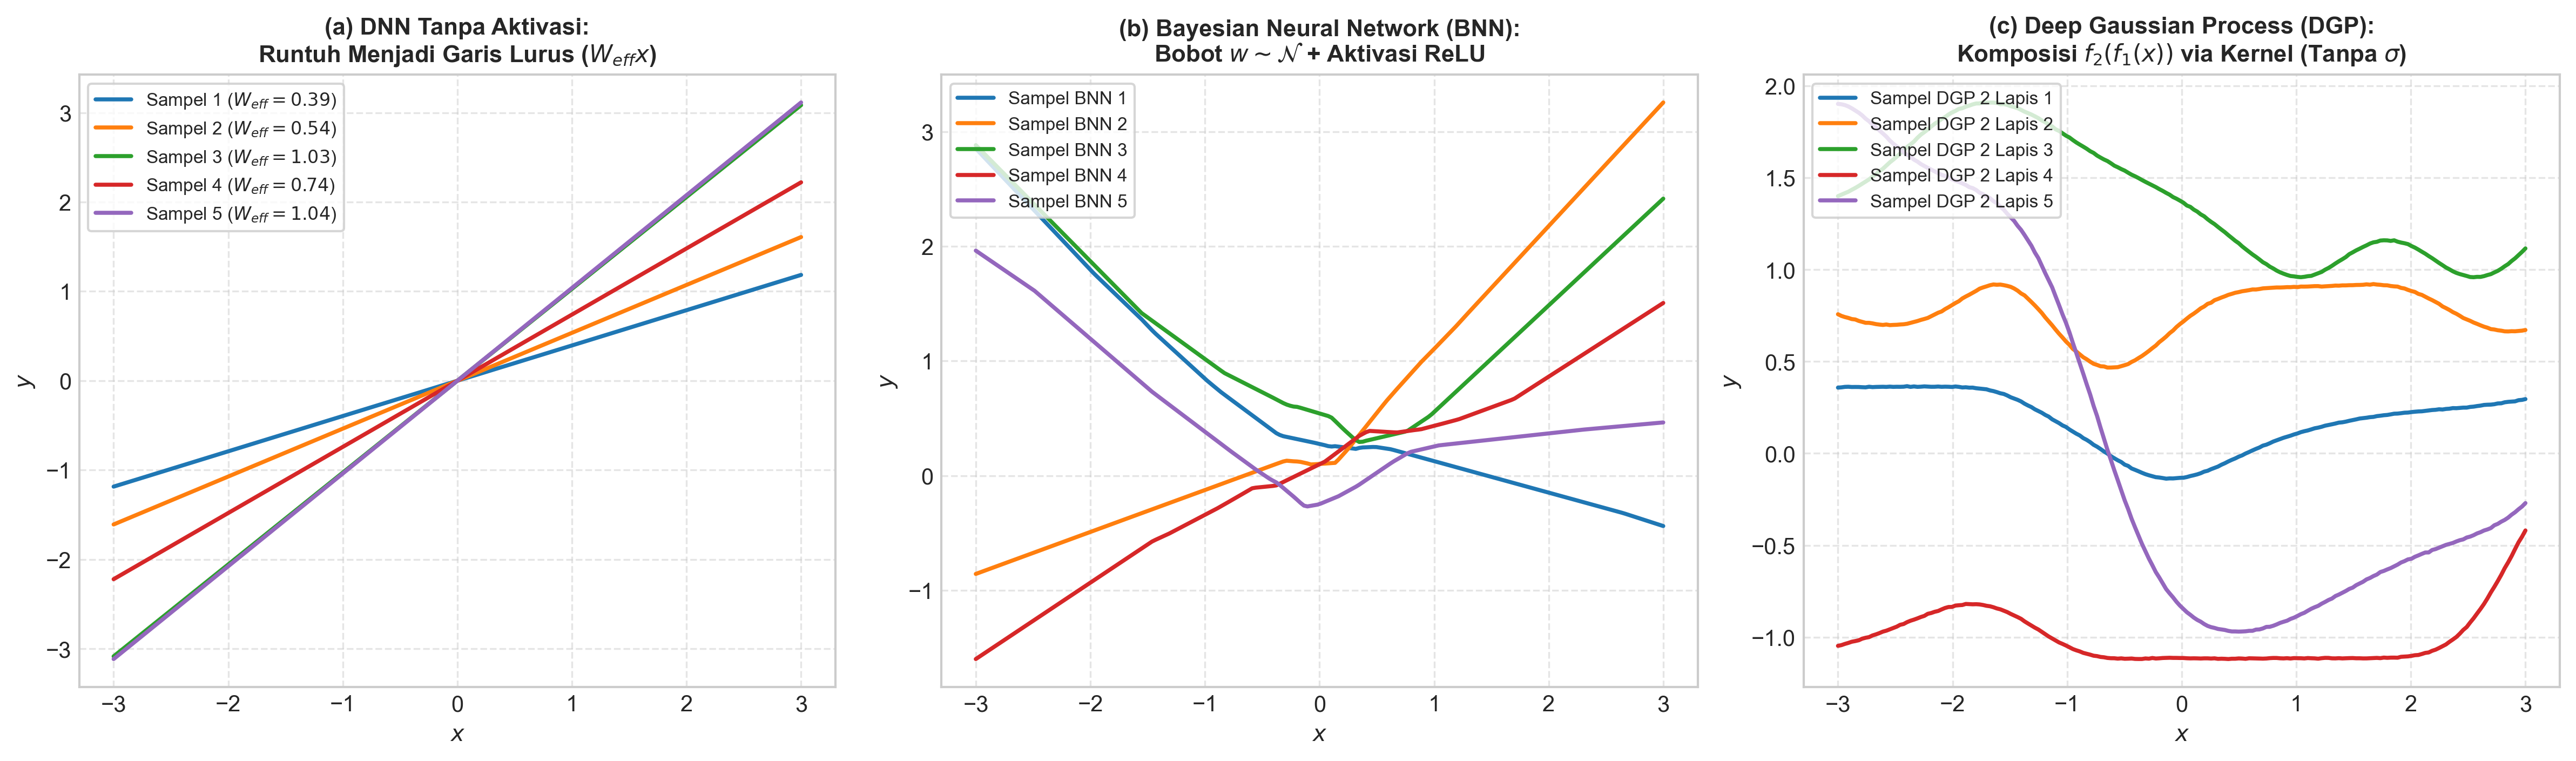

In [6]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=300)

x = np.linspace(-3, 3, 200)

# -------------------------------------------------------------
# Panel 1: Mengapa DNN Tanpa Aktivasi Runtuh (Linear Collapse)
# -------------------------------------------------------------
np.random.seed(12)
ax1 = axes[0]
for trial in range(5):
    # 5 lapisan linier berturut-turut tanpa aktivasi: W5 * W4 * W3 * W2 * W1 * x
    w_eff = 1.0
    for l in range(5):
        w_eff *= np.random.normal(1.0, 0.4)
    ax1.plot(x, w_eff * x, lw=1.8, label=f'Sampel {trial+1} ($W_{{eff}}={w_eff:.2f}$)')

ax1.set_title('(a) DNN Tanpa Aktivasi:\nRuntuh Menjadi Garis Lurus ($W_{eff} x$)', fontweight='bold', fontsize=10.5)
ax1.set_xlabel('$x$'); ax1.set_ylabel('$y$')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left', fontsize=8, frameon=True)

# -------------------------------------------------------------
# Panel 2: Bayesian Neural Network (Sampling Bobot Parametrik)
# -------------------------------------------------------------
np.random.seed(42)
ax2 = axes[1]
n_hidden = 20
for sample in range(5):
    # Bobot w ~ N(0, 1) berdistribusi, dengan aktivasi ReLU
    W1 = np.random.normal(0, 1.2, size=(n_hidden, 1))
    b1 = np.random.normal(0, 0.8, size=(n_hidden, 1))
    W2 = np.random.normal(0, 1.0, size=(1, n_hidden)) / np.sqrt(n_hidden)
    
    # Forward pass BNN dengan fungsi aktivasi ReLU
    h = np.maximum(0, W1 @ x.reshape(1, -1) + b1)
    y_bnn = (W2 @ h).flatten()
    ax2.plot(x, y_bnn, lw=1.8, label=f'Sampel BNN {sample+1}')

ax2.set_title('(b) Bayesian Neural Network (BNN):\nBobot $w \sim \mathcal{N}$ + Aktivasi ReLU', fontweight='bold', fontsize=10.5)
ax2.set_xlabel('$x$'); ax2.set_ylabel('$y$')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left', fontsize=8, frameon=True)

# -------------------------------------------------------------
# Panel 3: DGP Layer (Fungsi Acak Non-Parametrik via Kernel RBF)
# -------------------------------------------------------------
np.random.seed(42)
ax3 = axes[2]

def rbf_kernel(x1, x2, lengthscale=1.0, variance=1.0):
    dist_sq = (x1[:, None] - x2[None, :]) ** 2
    return variance * np.exp(-0.5 * dist_sq / (lengthscale ** 2))

# Lapisan 1: GP dengan kernel RBF
K1 = rbf_kernel(x, x, lengthscale=1.2, variance=1.0) + 1e-6 * np.eye(len(x))
L1 = np.linalg.cholesky(K1)

for sample in range(5):
    # Tarik sampel fungsi f1 ~ GP(0, K1)
    u1 = np.random.normal(0, 1, size=len(x))
    h1 = L1 @ u1  # Output lapisan 1 (tanpa fungsi aktivasi!)
    
    # Lapisan 2: Input adalah h1, kernel K2 dihitung langsung dari h1
    K2 = rbf_kernel(h1, h1, lengthscale=1.5, variance=1.0) + 1e-6 * np.eye(len(h1))
    L2 = np.linalg.cholesky(K2)
    u2 = np.random.normal(0, 1, size=len(h1))
    y_dgp = L2 @ u2  # Output DGP 2 lapis
    
    ax3.plot(x, y_dgp, lw=1.8, label=f'Sampel DGP 2 Lapis {sample+1}')

ax3.set_title('(c) Deep Gaussian Process (DGP):\nKomposisi $f_2(f_1(x))$ via Kernel (Tanpa $\sigma$)', fontweight='bold', fontsize=10.5)
ax3.set_xlabel('$x$'); ax3.set_ylabel('$y$')
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.legend(loc='upper left', fontsize=8, frameon=True)

plt.tight_layout()
plt.show()



---
# 🌌 Memahami Ruang Hilbert (*Hilbert Space*): Dari Geometri Euclidean Menuju Ruang Fungsi Tak Terhingga

> **Pertanyaan**:  
> *"Saya belum pernah mendengar tentang Ruang Hilbert, tolong jelaskan."*

---

## 🧭 1. Intuisi Awal: Memperluas Geometri Biasa ke Dunia Fungsi

Untuk memahami Ruang Hilbert tanpa tersesat dalam keabstrakan matematika tinggi, mari kita mulai dari geometri dasar yang sudah sangat kita kenal di sekolah: **Ruang Euclidean $\mathbb{R}^2$ atau $\mathbb{R}^3$**.

Di ruang $\mathbb{R}^3$, elemen ruang adalah **vektor angka**, misalnya $\mathbf{u} = (u_1, u_2, u_3)$ dan $\mathbf{v} = (v_1, v_2, v_3)$. Di ruang ini, kita memiliki konsep geometris yang sangat jelas:
1. **Perkalian Titik (*Dot Product / Inner Product*)**:
   $$\langle \mathbf{u}, \mathbf{v} \rangle = \mathbf{u} \cdot \mathbf{v} = u_1 v_1 + u_2 v_2 + u_3 v_3$$
2. **Panjang Vektor (*Norm*)**:
   $$\|\mathbf{u}\| = \sqrt{\langle \mathbf{u}, \mathbf{u} \rangle} = \sqrt{u_1^2 + u_2^2 + u_3^2}$$
3. **Jarak (*Distance*) Antara Dua Vektor**:
   $$d(\mathbf{u}, \mathbf{v}) = \|\mathbf{u} - \mathbf{v}\| = \sqrt{(u_1 - v_1)^2 + (u_2 - v_2)^2 + (u_3 - v_3)^2}$$
4. **Sudut & Ketegaklurusan (*Orthogonality*)**:
   $$\cos \theta = \frac{\langle \mathbf{u}, \mathbf{v} \rangle}{\|\mathbf{u}\| \|\mathbf{v}\|}$$
   Jika $\langle \mathbf{u}, \mathbf{v} \rangle = 0$, maka kedua vektor tersebut **saling tegak lurus (ortogonal)**.

---

### 🤔 Pertanyaan Lompatan Berpikir:
> *Bagaimana jika "titik" atau "elemen" di dalam ruang tersebut **bukan lagi vektor angka berdimensi 3**, melainkan **sebuah fungsi utuh**, seperti $f(x) = \sin(x)$ dan $g(x) = x^2$?*

* Apakah kita bisa mengukur **panjang** dari sebuah fungsi $f(x)$?
* Apakah kita bisa mengukur **jarak** antara dua fungsi $f(x)$ dan $g(x)$?
* Apakah kita bisa mengukur **sudut** atau menyatakan dua fungsi **saling tegak lurus**?
* Apakah kita bisa melakukan **proyeksi ortogonal** sebuah fungsi ke fungsi lain?

**Jawabannya: BISA!**  
Wadah matematis yang memungkinkan kita menerapkan seluruh geometri Euclidean (panjang, jarak, sudut, proyeksi, ortogonalitas) ke dalam himpunan objek **berdimensi tak terhingga (seperti fungsi)** dinamakan **RUANG HILBERT (*Hilbert Space*)**, yang dinamai untuk menghormati matematikawan besar Jerman, **David Hilbert (1862–1943)**.

---

## 🧱 2. Definisi Formal: Hierarki 4 Tingkatan Ruang

Secara matematis yang presisi, Ruang Hilbert didefinisikan sebagai:
$$\textbf{Ruang Hilbert} \; (\mathcal{H}) = \textbf{Ruang Hasil Kali Dalam yang Lengkap} \; (\textit{Complete Inner Product Space})$$

Mari kita bedah 4 tingkatan pembentuknya secara berurutan:

```
[ Ruang Vektor ] (Bisa menjumlahkan dan mengalikan skalar)
       ↓  + Operasi Panjang
[ Ruang Bernorma / Normed Space ] (Memiliki ukuran panjang ||v||)
       ↓  + Operasi Sudut / Dot Product
[ Ruang Hasil Kali Dalam / Inner Product Space ] (Memiliki perkalian titik ⟨u, v⟩)
       ↓  + Sifat "Tidak Ada Lubang" (Kelengkapan Cauchy)
[ RUANG HILBERT (ℋ) ] (Lengkap secara topologis & memiliki geometri inner product)
```

1. **Ruang Vektor (*Vector Space*)**:
   Himpunan fungsi di mana penjumlahan dua fungsi $(f + g)(x) = f(x) + g(x)$ dan perkalian skalar $(c \cdot f)(x) = c \cdot f(x)$ masih menghasilkan fungsi di dalam himpunan tersebut.
2. **Ruang Hasil Kali Dalam (*Inner Product Space*)**:
   Ruang vektor yang dilengkapi operasi $\langle f, g \rangle \in \mathbb{R}$ yang memenuhi 3 syarat:
   * **Simetri**: $\langle f, g \rangle = \langle g, f \rangle$
   * **Linieritas**: $\langle a f_1 + b f_2, \; g \rangle = a \langle f_1, g \rangle + b \langle f_2, g \rangle$
   * **Definit Positif**: $\langle f, f \rangle \ge 0$, dan $\langle f, f \rangle = 0 \iff f = 0$.
   Dari hasil kali dalam, panjang/norm otomatis terdefinisi: $\|f\| = \sqrt{\langle f, f \rangle}$.
3. **Kelengkapan (*Completeness / Cauchy Complete*)**:
   Suatu ruang disebut **lengkap** jika setiap barisan elemen yang jarak antar-titiknya semakin merapat (*barisan Cauchy*) dijamin akan berkonvergen menuju elemen yang **tetap berada di dalam ruang itu sendiri** (ruang tersebut tidak memiliki "titik bolong").  
   *(Analogi: Bilangan Rasional $\mathbb{Q}$ tidak lengkap karena barisan pecahan bisa berkonvergen ke $\sqrt{2}$ yang bukan bilangan rasional. Sedangkan Bilangan Real $\mathbb{R}$ lengkap).*

---

## 📐 3. Contoh Paling Terkenal: Ruang Fungsi $L^2[a, b]$

Ruang Hilbert yang paling intuitif adalah ruang **$L^2[a, b]$**, yaitu himpunan seluruh fungsi kontinu/terintegralkan yang energinya berhingga:
$$L^2[a, b] = \left\{ f : [a, b] \to \mathbb{R} \;\middle|\; \int_a^b (f(x))^2 dx < \infty \right\}$$

Bagaimana operasi geometris dihitung di ruang ini?

| Konsep Geometri | Pada Vektor Biasa $\mathbb{R}^n$ | Pada Ruang Fungsi Hilbert $L^2[a, b]$ |
| :--- | :--- | :--- |
| **Elemen** | Vektor angka $\mathbf{u} = [u_1, \dots, u_n]^T$ | Fungsi kontinyu $f(x)$ (dimensi tak terhingga) |
| **Inner Product** | $\langle \mathbf{u}, \mathbf{v} \rangle = \sum_{i=1}^n u_i v_i$ | $\langle f, g \rangle_{L^2} = \int_a^b f(x) g(x) \, dx$ |
| **Panjang (Norm)** | $\|\mathbf{u}\| = \sqrt{\sum_{i=1}^n u_i^2}$ | $\|f\|_{L^2} = \sqrt{\int_a^b (f(x))^2 \, dx}$ |
| **Jarak (Distance)** | $d(\mathbf{u}, \mathbf{v}) = \sqrt{\sum_{i=1}^n (u_i - v_i)^2}$ | $d(f, g) = \|f - g\|_{L^2} = \sqrt{\int_a^b (f(x) - g(x))^2 \, dx}$ |
| **Ketegaklurusan** | $\sum_{i=1}^n u_i v_i = 0 \iff \mathbf{u} \perp \mathbf{v}$ | $\int_a^b f(x) g(x) \, dx = 0 \iff f \perp g$ |

> 💡 **Contoh Nyata Ortogonalitas Fungsi**:  
> Di interval $[-\pi, \pi]$, fungsi $f(x) = \sin(x)$ dan $g(x) = \cos(x)$ adalah **dua vektor yang saling tegak lurus di Ruang Hilbert**, karena:
> $$\langle \sin, \cos \rangle = \int_{-\pi}^\pi \sin(x) \cos(x) \, dx = \left[ \frac{1}{2} \sin^2(x) \right]_{-\pi}^\pi = 0 - 0 = 0$$
> Konsep inilah yang menjadi fondasi seluruh **Analisis Fourier**, pengolahan sinyal, dan mekanika kuantum!

---

## 🤖 4. Mengapa Ruang Hilbert Sangat Krusial di Machine Learning & Gaussian Process?

Dalam Machine Learning, konsep Ruang Hilbert muncul dalam bentuk khusus yang disebut:  
**RKHS (*Reproducing Kernel Hilbert Space*)**.

### A. Trik Kernel (*The Kernel Trick*) & Teorema Mercer
Misalkan kita ingin memetakan data non-linier $\mathbf{x} \in \mathbb{R}^d$ ke ruang fitur berdimensi sangat tinggi (bahkan tak terhingga) $\phi(\mathbf{x})$ agar data dapat dipisahkan secara linier.  
Menghitung vektor tak berhingga $\phi(\mathbf{x})$ secara langsung adalah mustahil. Namun, **Teorema Mercer** menyatakan:
> *Setiap fungsi kernel definit positif $k(\mathbf{x}, \mathbf{x}')$ bersesuaian secara eksak dengan hasil kali dalam (*inner product*) di suatu Ruang Hilbert $\mathcal{H}$*:
> $$k(\mathbf{x}, \mathbf{x}') = \langle \phi(\mathbf{x}), \; \phi(\mathbf{x}') \rangle_{\mathcal{H}}$$

Sebagai contoh, pada **Kernel RBF (Squared Exponential)**:
$$k(x, x') = \exp\left( -\frac{(x - x')^2}{2l^2} \right)$$
Jika kita mengekspansikan fungsi eksponensial di atas menggunakan deret Taylor tak terhingga:
$$\exp(z) = \sum_{n=0}^\infty \frac{z^n}{n!} = 1 + z + \frac{z^2}{2!} + \frac{z^3}{3!} + \dots$$
Maka vektor fitur $\phi(x)$ sebenarnya adalah vektor **berdimensi tak hingga**:
$$\phi(x) = \exp\left(-\frac{x^2}{2l^2}\right) \left[ 1, \; \frac{x}{l}, \; \frac{x^2}{\sqrt{2!} l^2}, \; \frac{x^3}{\sqrt{3!} l^3}, \; \dots \right]^T$$
Kita tidak perlu menghitung vektor tak terhingga tersebut; cukup hitung $k(x, x')$ dalam satu baris kode! Itulah keajaiban Ruang Hilbert.

---

### B. Sifat Reproduksi (*The Reproducing Property*)
Pada Ruang Hilbert biasa (seperti $L^2$), mengevaluasi nilai fungsi di satu titik $f(x)$ tidak selalu stabil.  
Namun pada **RKHS (Reproducing Kernel Hilbert Space)** $\mathcal{H}_k$, terdapat sifat istimewa di mana **evaluasi fungsi di titik $x$ setara dengan perkalian titik fungsi tersebut dengan kernel yang berpusat di $x$**:
$$f(x) = \langle f, \; k(\cdot, x) \rangle_{\mathcal{H}_k}$$
Kernel $k(\cdot, x)$ bertindak seperti *vektor representasi evaluasi titik* di dalam ruang Hilbert!

---

### C. Kaitannya dengan Gaussian Process (GP) & Deep Gaussian Process (DGP)
1. **Solusi Rata-rata GP Posterior Ada di RKHS**:  
   Ketika kita melatih Gaussian Process Regression pada data latih $\{(\mathbf{x}_i, y_i)\}_{i=1}^n$, prediksi rata-rata $\mu_*(\mathbf{x})$ untuk titik baru adalah:
   $$\mu_*(\mathbf{x}) = \sum_{i=1}^n \alpha_i \, k(\mathbf{x}, \mathbf{x}_i), \quad \text{dengan } \boldsymbol{\alpha} = (K + \sigma_n^2 I)^{-1} \mathbf{y}$$
   Fungsi prediksi $\mu_*(\mathbf{x})$ ini **secara eksak merupakan elemen dari Ruang Hilbert $\mathcal{H}_k$**, dan menurut **Representer Theorem**, ini adalah fungsi terhalus di $\mathcal{H}_k$ yang meminimalkan galat empiris.
2. **Keterkaitan pada DGP**:  
   Pada Deep Gaussian Process, setiap lapisan $\ell$ adalah penarikan sampel fungsi dari proses Gaussian:
   $$\mathbf{f}^{(\ell)} \sim \mathcal{GP}\left(\mathbf{0}, \; k^{(\ell)}\right)$$
   Masing-masing lapisan tersembunyi tersebut memproyeksikan representasi data melalui **Ruang Hilbert berdimensi tak terhingga $\mathcal{H}_{k^{(\ell)}}$** yang ditentukan oleh kernel masing-masing lapisan, tanpa membutuhkan neuron berhingga maupun fungsi aktivasi $\sigma(\cdot)$!

---

### 📝 Ringkasan 1 Kalimat:
> **Ruang Hilbert adalah ruang vektor berdimensi tak terhingga yang lengkap dan memiliki aturan perkalian titik (*inner product*), sehingga kita bisa mengukur panjang, jarak, dan sudut antar-fungsi secara geometris layaknya vektor biasa di ruang 3 dimensi.**


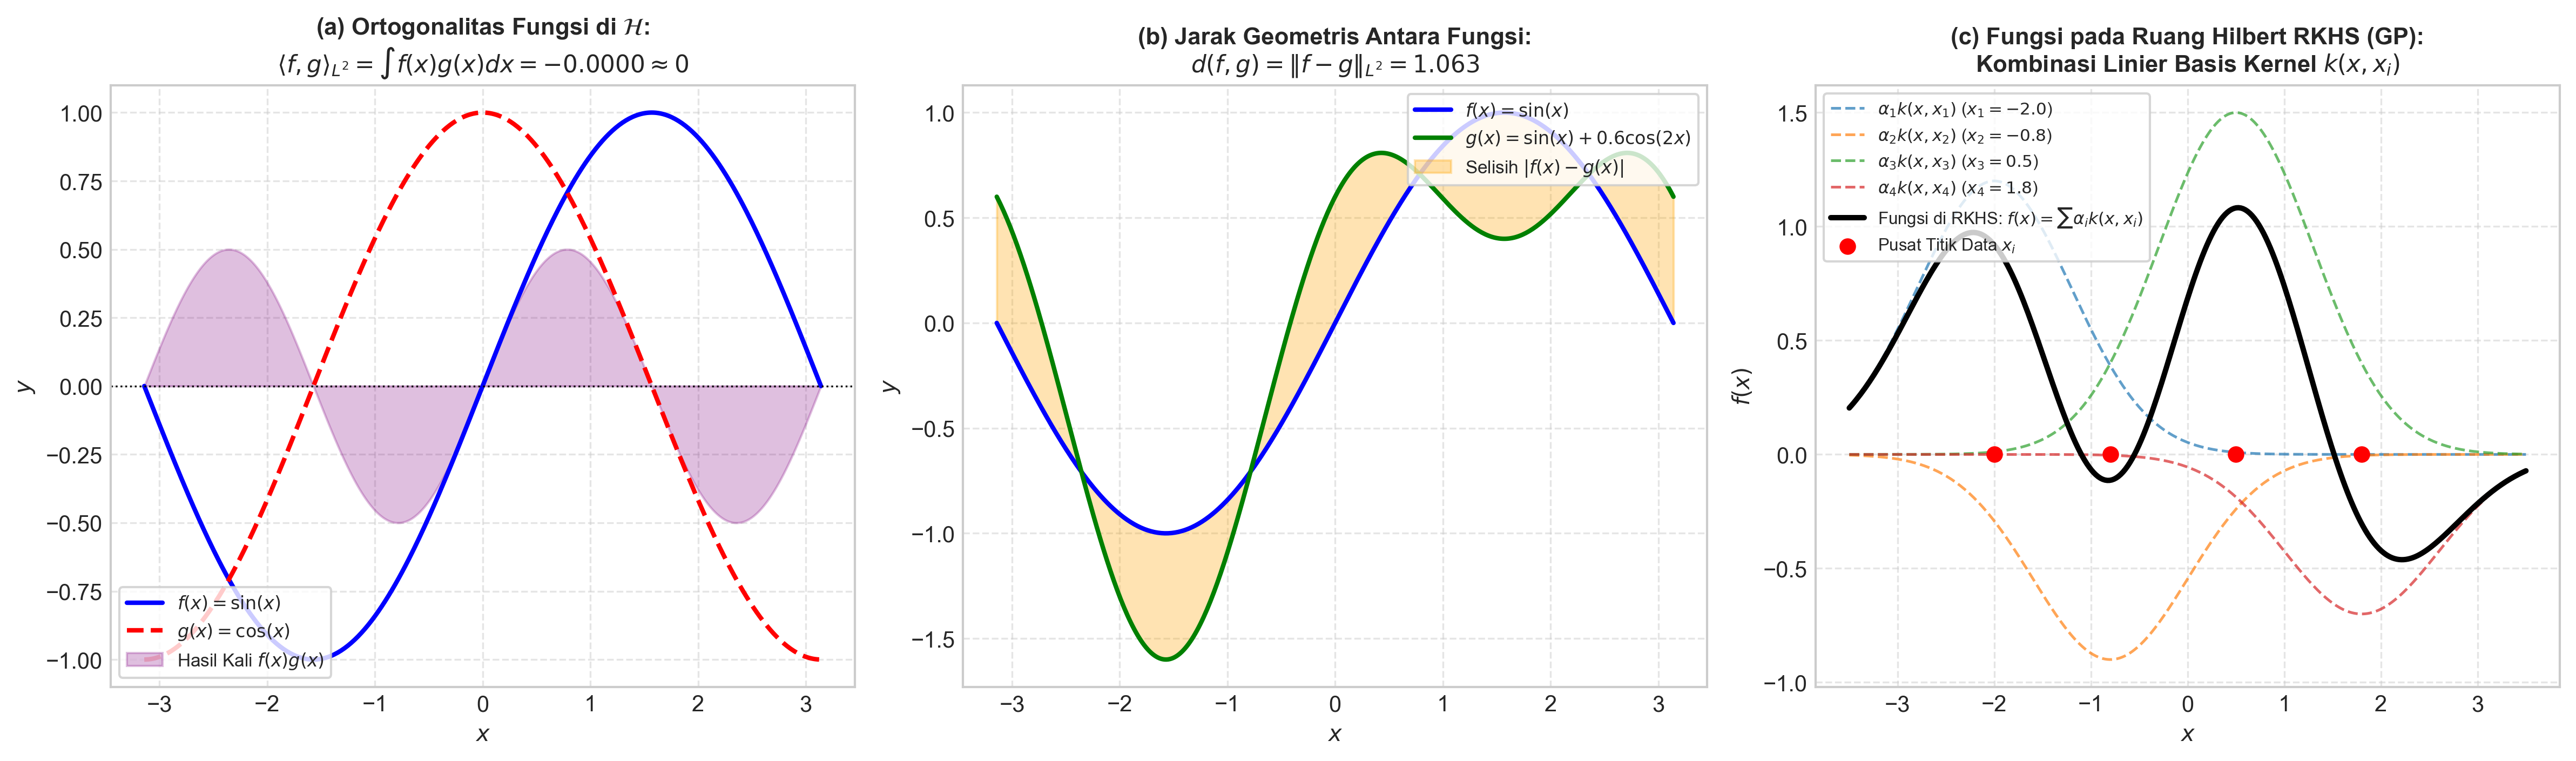

In [7]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=300)

x = np.linspace(-np.pi, np.pi, 400)

# =========================================================================
# Panel 1: Konsep Ortogonalitas Fungsi di Ruang Hilbert L2[-pi, pi]
# =========================================================================
ax1 = axes[0]
f1 = np.sin(x)
f2 = np.cos(x)

# Hitung inner product via integrasi numerik: <f, g> = int_{-pi}^{pi} f(x)g(x) dx
inner_prod = np.trapezoid(f1 * f2, x)

ax1.plot(x, f1, 'b-', lw=2, label=r'$f(x) = \sin(x)$')
ax1.plot(x, f2, 'r--', lw=2, label=r'$g(x) = \cos(x)$')
ax1.fill_between(x, f1 * f2, color='purple', alpha=0.25, label=r'Hasil Kali $f(x)g(x)$')
ax1.axhline(0, color='black', lw=0.8, linestyle=':')

ax1.set_title(f'(a) Ortogonalitas Fungsi di $\\mathcal{{H}}$:\n$\\langle f, g \\rangle_{{L^2}} = \\int f(x)g(x)dx = {inner_prod:.4f} \\approx 0$', fontweight='bold', fontsize=10.5)
ax1.set_xlabel('$x$'); ax1.set_ylabel('$y$')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower left', fontsize=8, frameon=True)

# =========================================================================
# Panel 2: Konsep Jarak Antara Dua Fungsi: d(f, g) = ||f - g||_L2
# =========================================================================
ax2 = axes[1]
g1 = np.sin(x)
g2 = np.sin(x) + 0.6 * np.cos(2 * x)

# Jarak Hilbert: sqrt( int (g1 - g2)^2 dx )
selisih_kuadrat = (g1 - g2) ** 2
dist_hilbert = np.sqrt(np.trapezoid(selisih_kuadrat, x))

ax2.plot(x, g1, 'b-', lw=2, label=r'$f(x) = \sin(x)$')
ax2.plot(x, g2, 'g-', lw=2, label=r'$g(x) = \sin(x) + 0.6\cos(2x)$')
ax2.fill_between(x, g1, g2, color='orange', alpha=0.3, label=r'Selisih $|f(x) - g(x)|$')

ax2.set_title(f'(b) Jarak Geometris Antara Fungsi:\n$d(f, g) = \\|f - g\\|_{{L^2}} = {dist_hilbert:.3f}$', fontweight='bold', fontsize=10.5)
ax2.set_xlabel('$x$'); ax2.set_ylabel('$y$')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right', fontsize=8, frameon=True)

# =========================================================================
# Panel 3: Representasi Fungsi di RKHS via Basis Kernel RBF
# =========================================================================
ax3 = axes[2]
centers = np.array([-2.0, -0.8, 0.5, 1.8])
weights = np.array([1.2, -0.9, 1.5, -0.7])
lengthscale = 0.8

x_dense = np.linspace(-3.5, 3.5, 300)
f_rkhs = np.zeros_like(x_dense)

for i, (c, w) in enumerate(zip(centers, weights)):
    # Basis kernel RBF
    k_i = np.exp(-0.5 * ((x_dense - c) / lengthscale) ** 2)
    component = w * k_i
    f_rkhs += component
    ax3.plot(x_dense, component, linestyle='--', lw=1.2, alpha=0.7, label=f'$\\alpha_{{{i+1}}} k(x, x_{{{i+1}}})$ ($x_{{{i+1}}}={c}$)')

# Fungsi total di RKHS
ax3.plot(x_dense, f_rkhs, 'k-', lw=2.4, label=r'Fungsi di RKHS: $f(x) = \sum \alpha_i k(x, x_i)$')
ax3.scatter(centers, np.zeros_like(centers), color='red', s=40, zorder=5, label='Pusat Titik Data $x_i$')

ax3.set_title('(c) Fungsi pada Ruang Hilbert RKHS (GP):\nKombinasi Linier Basis Kernel $k(x, x_i)$', fontweight='bold', fontsize=10.5)
ax3.set_xlabel('$x$'); ax3.set_ylabel('$f(x)$')
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.legend(loc='upper left', fontsize=7.5, frameon=True)

plt.tight_layout()
plt.show()



---
# 🎯 Eksperimen Interpolasi Celah Data (*Gap / Missing Data Imputation*) Menggunakan Gaussian Process

> **Pertanyaan**:  
> *"Jika saya melakukan interpolasi dari data yang tidak ada pada data training, apakah bisa? Bisa tolong buatkan contohnya di coret.ipynb?"*

---

## 💡 1. Jawaban Langsung: YA, SANGAT BISA!
> **Interpolasi data yang hilang (*missing data / data gap*) justru merupakan keunggulan terbesar dan aplikasi paling klasik dari Gaussian Process!**  
> Dalam sejarah matematika dan geostatistika, metode ini dikenal sebagai **Kriging** (dikembangkan oleh Dan Krige & Georges Matheron), yang awalnya dipakai untuk memetakan konsentrasi mineral di titik-titik tanah yang tidak diambil sampel bornya.

---

## 🔍 2. Perbedaan Fundamental: Interpolasi vs Ekstrapolasi

* **Interpolasi**:
  Memprediksi nilai pada titik $x_*$ yang berada **di dalam rentang data latih** ($x_{\min} < x_* < x_{\max}$), tetapi titik spesifik $x_*$ tersebut **tidak pernah diobservasi** (misalnya sensor mati selama beberapa hari, data rusak, atau pengamatan hilang).
* **Ekstrapolasi**:
  Memprediksi nilai pada titik $x_*$ yang berada **di luar jangkauan masa lalu** ($x_* > x_{\max}$ atau $x_* < x_{\min}$), misalnya meramal cuaca atau emisi $\text{CO}_2$ untuk tahun depan.

---

## 📐 3. Karakteristik Magis Interpolasi Gaussian Process

Ketika GP melakukan interpolasi pada sebuah celah data (*gap*), terjadi dua fenomena unik:

1. **Jembatan Rata-Rata (*Posterior Mean Bridge*)**:
   $$\mu_*(x_*) = \sum_{i=1}^n \alpha_i \cdot k(x_*, x_i)$$
   Fungsi kernel $k(x_*, x_i)$ mengukur korelasi titik hilang $x_*$ terhadap data tetangga di sebelah kiri dan sebelah kanan celah. GP secara otomatis membentuk jembatan kurva halus yang menghubungkan kedua wilayah data secara kontinu.

2. **Gelembung Ketidakpastian (*Uncertainty Bulge*)**:
   $$\sigma_*^2(x_*) = k(x_*, x_*) - \mathbf{k}_*^T K_y^{-1} \mathbf{k}_*$$
   * Tepat pada titik di mana ada data latih: $\sigma_*^2 \approx \sigma_n^2$ (keraguan model mendekati nol / sangat yakin).
   * Pada celah di mana data hilang: Nilai korelasi $\mathbf{k}_*$ terhadap data latih mengecil, sehingga nilai variansi $\sigma_*^2(x_*)$ **menggelembung naik secara proporsional terhadap lebar celah**.
   * Ini membuktikan sifat **"kejujuran probabilistik"** GP: model tahu persis kapan ia memiliki informasi yang cukup dan kapan ia sedang berspekulasi di wilayah tanpa data!

3. **Keunggulan Dibanding Interpolasi Klasik (Spline / Polinomial)**:
   * Interpolasi polinomial derajat tinggi rentan mengalami **Fenomena Runge** (osilasi liar tak terkendali di daerah kosong).
   * Interpolasi *Linear* / *Spline* hanya memberikan satu garis tebakan tanpa memberi tahu berapa margin kesalahan tebakan tersebut.
   * GP memberikan **kurva rata-rata yang stabil sekaligus pita kepercayaan $95\%$ ($\mu_* \pm 2\sigma_*$)**.

---

Mari kita buktikan lewat simulasi numerik interaktif di bawah ini: kita buat sebuah skenario di mana sebuah sensor merekam fungsi non-linier, namun **sensor mati total di interval tengah $x \in [-1.2, 1.2]$ (terdapat lubang data yang besar)**. Kita akan uji kemampuan interpolasi GP dalam merekonstruksi data yang hilang tersebut.


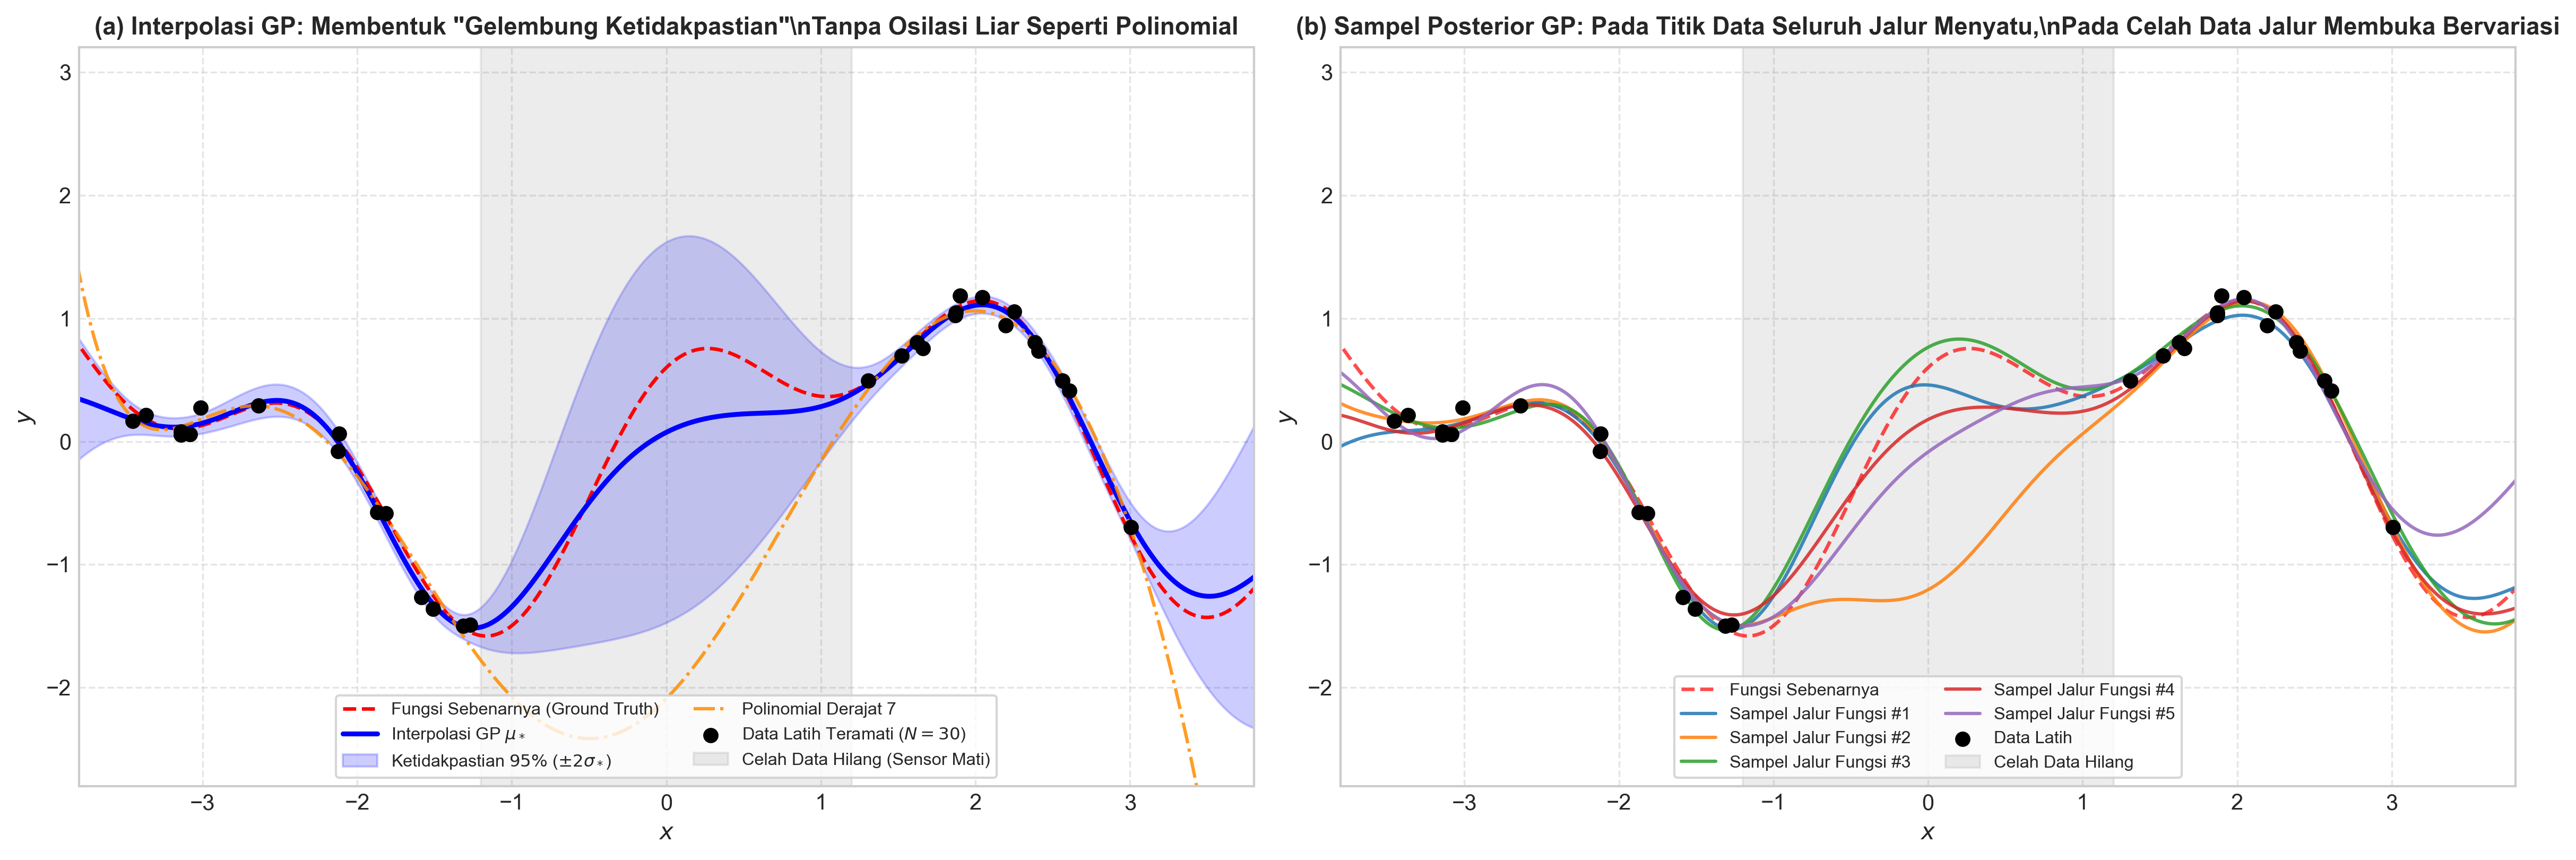

EVALUASI REKONSTRUKSI INTERPOLASI KHUSUS DI WILAYAH CELAH DATA HILANG [-1.2, 1.2]:
• Mean Squared Error (MSE) Interpolasi Gaussian Process : 0.1048
• Mean Squared Error (MSE) Interpolasi Polinomial Orde 7 : 3.1655
• Rata-rata Lebar Pita Ketidakpastian (+- 2 sigma) di Celah : 1.9361
• Rata-rata Lebar Pita Ketidakpastian (+- 2 sigma) di Data  : 0.4995


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), dpi=300)

# 1. Definisi Fungsi Nyata yang Menghasilkan Data
def true_function(x):
    return np.sin(1.2 * x) + 0.6 * np.cos(2.8 * x)

# 2. Bangkitkan Data Latih dengan CELAH BESAR DI TENGAH (Missing Data Gap)
np.random.seed(42)
# Wilayah kiri: [-3.5 s.d. -1.2]
x_left = np.random.uniform(-3.5, -1.2, size=15)
# Wilayah kanan: [1.2 s.d. 3.5]
x_right = np.random.uniform(1.2, 3.5, size=15)
# GABUNGKAN TANPA INTERVAL [-1.2, 1.2] (Celah kosong = Sensor Mati)
X_train = np.sort(np.concatenate([x_left, x_right]))[:, None]
y_train = true_function(X_train.flatten()) + np.random.normal(0, 0.08, size=len(X_train))

# Grid padat untuk evaluasi interpolasi pada seluruh domain
x_dense = np.linspace(-4.0, 4.0, 400)[:, None]
y_true_dense = true_function(x_dense.flatten())

# 3. Latih Gaussian Process Regressor
kernel = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale=1.0, length_scale_bounds=(0.2, 5.0))
gp = GaussianProcessRegressor(kernel=kernel, alpha=0.08**2, n_restarts_optimizer=5, random_state=42)
gp.fit(X_train, y_train)

# Prediksi posterior: mean dan standar deviasi
y_mean, y_std = gp.predict(x_dense, return_std=True)

# 4. Sebagai Pembanding: Interpolasi Polinomial Orde 7
poly_coeffs = np.polyfit(X_train.flatten(), y_train, deg=7)
y_poly = np.polyval(poly_coeffs, x_dense.flatten())

# =========================================================================
# PANEL 1: Interpolasi GP vs Polinomial pada Celah Kosong
# =========================================================================
# Plot fungsi asli
ax1.plot(x_dense, y_true_dense, 'r--', lw=1.6, label='Fungsi Sebenarnya (Ground Truth)')

# Plot prediksi GP dan pita ketidakpastian
ax1.plot(x_dense, y_mean, 'b-', lw=2.2, label=r'Interpolasi GP $\mu_*$')
ax1.fill_between(
    x_dense.flatten(), y_mean - 2 * y_std, y_mean + 2 * y_std,
    color='blue', alpha=0.20, label=r'Ketidakpastian $95\%$ ($\pm 2\sigma_*$)'
)

# Plot interpolasi polinomial (menunjukkan kelemahannya)
ax1.plot(x_dense, y_poly, color='darkorange', linestyle='-.', lw=1.5, alpha=0.85, label='Polinomial Derajat 7')

# Plot data latih yang ada
ax1.scatter(X_train, y_train, c='black', s=35, zorder=5, label=f'Data Latih Teramati ($N={len(X_train)}$)')

# Highlight wilayah celah data yang hilang
ax1.axvspan(-1.2, 1.2, color='gray', alpha=0.15, label='Celah Data Hilang (Sensor Mati)')

ax1.set_title('(a) Interpolasi GP: Membentuk "Gelembung Ketidakpastian"\\nTanpa Osilasi Liar Seperti Polinomial', fontweight='bold', fontsize=11)
ax1.set_xlabel('$x$', fontsize=10.5); ax1.set_ylabel('$y$', fontsize=10.5)
ax1.set_ylim(-2.8, 3.2); ax1.set_xlim(-3.8, 3.8)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower center', fontsize=7.8, frameon=True, ncol=2)

# =========================================================================
# PANEL 2: Sampel Fungsi Acak dari Distribusi Posterior GP
# =========================================================================
# Tarik 5 realisasi fungsi kontinu dari GP posterior
np.random.seed(101)
y_samples = gp.sample_y(x_dense, n_samples=5, random_state=42)

ax2.plot(x_dense, y_true_dense, 'r--', lw=1.6, alpha=0.7, label='Fungsi Sebenarnya')
for i in range(5):
    ax2.plot(x_dense, y_samples[:, i], lw=1.5, alpha=0.85, label=f'Sampel Jalur Fungsi #{i+1}')

ax2.scatter(X_train, y_train, c='black', s=35, zorder=5, label='Data Latih')
ax2.axvspan(-1.2, 1.2, color='gray', alpha=0.15, label='Celah Data Hilang')

ax2.set_title('(b) Sampel Posterior GP: Pada Titik Data Seluruh Jalur Menyatu,\\nPada Celah Data Jalur Membuka Bervariasi', fontweight='bold', fontsize=11)
ax2.set_xlabel('$x$', fontsize=10.5); ax2.set_ylabel('$y$', fontsize=10.5)
ax2.set_ylim(-2.8, 3.2); ax2.set_xlim(-3.8, 3.8)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='lower center', fontsize=7.8, frameon=True, ncol=2)

plt.tight_layout()
plt.show()

# Evaluasi galat rekonstruksi khusus di dalam wilayah celah
mask_gap = (x_dense.flatten() >= -1.2) & (x_dense.flatten() <= 1.2)
mse_gp_gap = np.mean((y_true_dense[mask_gap] - y_mean[mask_gap]) ** 2)
mse_poly_gap = np.mean((y_true_dense[mask_gap] - y_poly[mask_gap]) ** 2)

print("=" * 80)
print("EVALUASI REKONSTRUKSI INTERPOLASI KHUSUS DI WILAYAH CELAH DATA HILANG [-1.2, 1.2]:")
print("=" * 80)
print(f"• Mean Squared Error (MSE) Interpolasi Gaussian Process : {mse_gp_gap:.4f}")
print(f"• Mean Squared Error (MSE) Interpolasi Polinomial Orde 7 : {mse_poly_gap:.4f}")
print(f"• Rata-rata Lebar Pita Ketidakpastian (+- 2 sigma) di Celah : {np.mean(4 * y_std[mask_gap]):.4f}")
print(f"• Rata-rata Lebar Pita Ketidakpastian (+- 2 sigma) di Data  : {np.mean(4 * y_std[~mask_gap]):.4f}")
print("=" * 80)



---
# ⏱️ Kapan Sebenarnya Mean ($\mu_*$) dan Variansi ($\sigma_*^2$) Posterior Dihitung?
### *Membedakan Formula Analitik vs Waktu Eksekusi Angka Nyata (Training vs Inference)*

> **Pertanyaan**:  
> *"Bukankah mean dan variansi posteriornya sudah dihitung sebelumnya?"*

---

## 💡 1. Jawaban Langsung: Formula Analitiknya Sudah Ada, Tetapi Nilai Angkanya Baru Dihitung Saat Titik Uji ($x_*$) Diberikan!

Pertanyaan ini sangat penting karena menyangkut pemahaman siklus hidup (*lifecycle*) komputasi di machine learning:

1. **Formula Matematisnya (*The Equation*)**:  
   **YA, rumusnya memang sudah diturunkan sejak awal** dari sifat distribusi Gaussian gabungan (*joint Gaussian distribution*) pada Persamaan (2.19) buku GPML Rasmussen (2006):
   $$\mu_*(x_*) = \mathbf{k}_*^T K_y^{-1} \mathbf{y}$$
   $$\sigma_*^2(x_*) = k(x_*, x_*) - \mathbf{k}_*^T K_y^{-1} \mathbf{k}_*$$

2. **Evaluasi Nilai Angkanya (*The Concrete Number*)**:  
   **BELUM BISA DIHITUNG saat training!**  
   Perhatikan bahwa rumus di atas memuat suku $\mathbf{k}_* = k(X_{\text{train}}, x_*)$.  
   Selama Anda belum memberi tahu komputer titik $x_*$ mana yang ingin Anda tebak (apakah di celah $x=0.0$, atau di masa depan $x=5.0$), komputer **tidak mungkin bisa menghitung nilai angka $\mu_*$ dan $\sigma_*^2$ tersebut**.

---

### 🚗 Analogi Sederhana: Menghitung Jarak Tempuh
Bayangkan rumus fisika kecepatan konstan: $s(t) = v \times t$.
* **Saat Training (`gp.fit`)**: Mobil melaju dan Anda mengukur kecepatannya, didapat $v = 60\text{ km/jam}$.  
  Rumus Anda sekarang lengkap: $s(t) = 60 \cdot t$.  
  *Apakah jarak tempuh pada jam ke-3.5 ($s(3.5)$) sudah dihitung saat itu?* **Belum!**
* **Saat Inference (`gp.predict`)**: Seseorang bertanya: *"Berapa jarak yang ditempuh setelah $t = 3.5$ jam?"*  
  Barulah Anda menyuntikkan $t = 3.5$ ke dalam rumus: $s(3.5) = 60 \times 3.5 = 210\text{ km}$.

---

## 🔄 2. Garis Waktu Komputasi: Apa yang Dikerjakan Saat `fit()` vs `predict()`?

```
┌─────────────────────────────────────────────────────────────────────────────────────────────┐
│ TAHAP 1: TRAINING / FITTING (gp.fit(X_train, y_train))                                      │
├─────────────────────────────────────────────────────────────────────────────────────────────┤
│ Model HANYA melihat data latih X_train (n titik). Belum ada titik baru x*.                 │
│                                                                                             │
│ 1. Optimasi Hyperparameter Kernel: Mencari θ* (lengthscale, variansi) via Max Likelihood.   │
│ 2. Membentuk Matriks Kovariansi Latih: K_y = K(X, X) + σ_n² I    (Ukuran n x n)             │
│ 3. Faktorisasi Cholesky: L L^T = K_y                              (Komputasi O(n³))         │
│ 4. Menghitung Vektor Bobot Dual: α = K_y⁻¹ y = L⁻ᵀ (L⁻¹ y)       (Ukuran n x 1)             │
│                                                                                             │
│ Output yang Disimpan di Memori: kernel_, alpha_, X_train_, L_                              │
└─────────────────────────────────────────────────────────────────────────────────────────────┘
                                              │
                                              ▼
┌─────────────────────────────────────────────────────────────────────────────────────────────┐
│ TAHAP 2: INFERENCE / PREDIKSI / INTERPOLASI (gp.predict(x_*))                               │
├─────────────────────────────────────────────────────────────────────────────────────────────┤
│ Pengguna memberikan titik baru x_* (misalnya titik di dalam celah data yang hilang).        │
│                                                                                             │
│ 1. Menghitung Kemiripan Titik Baru terhadap Data Latih:                                     │
│    k_* = [k(x₁, x_*), k(x₂, x_*), ..., k(x_n, x_*)]ᵀ            (Ukuran n x 1)             │
│ 2. Menghitung Nilai Rata-rata Prediksi:                                                     │
│    μ_*(x_*) = k_*ᵀ α = ∑_{i=1}^n α_i k(x_*, x_i)                (Sangat Cepat: O(n))        │
│ 3. Menghitung Nilai Ketidakpastian Prediksi:                                                │
│    v = L⁻¹ k_*  ==>  σ_*(x_*) = √( k(x_*, x_*) - vᵀ v )         (Cepat: O(n²))             │
│                                                                                             │
│ Output: Angka riil μ_* dan interval ketidakpastian ± 2σ_* untuk titik spesifik x_*.        │
└─────────────────────────────────────────────────────────────────────────────────────────────┘
```

---

## 🔍 3. Mengapa Variansi $\sigma_*^2(x_*)$ Otomatis Menggelembung di Celah Data?

Perhatikan kembali persamaan analitik variansi:
$$\sigma_*^2(x_*) = \underbrace{k(x_*, x_*)}_{\text{Variansi Prior (Ketidakpastian Awal)}} - \underbrace{\mathbf{k}_*^T K_y^{-1} \mathbf{k}_*}_{\text{Informasi yang Diberikan oleh Data Latih}}$$

* Rumus ini **bahkan tidak memerlukan nilai label target $y$ sama sekali!** Ia murni bergantung pada letak geometris titik baru $x_*$ terhadap titik-titik data latih $X_{\text{train}}$.
* **Ketika $x_*$ berada tepat di atas data latih $x_i$**:  
  Nilai kemiripan $\mathbf{k}_*$ sangat tinggi $\rightarrow$ suku pengurang $\mathbf{k}_*^T K_y^{-1} \mathbf{k}_*$ bernilai maksimal $\rightarrow \sigma_*^2(x_*) \approx \sigma_n^2 \approx 0$ (sangat yakin).
* **Ketika $x_*$ berada di tengah-tengah celah data yang hilang (interpolasi)**:  
  Titik $x_*$ berjarak jauh dari titik data latih terdekat $\rightarrow$ seluruh elemen vektor $\mathbf{k}_*$ bernilai kecil mendekati 0 $\rightarrow$ suku pengurang menjadi sangat kecil $\rightarrow \sigma_*^2(x_*) \approx k(x_*, x_*)$ (ketidakpastian kembali membesar ke level prior awal!).

---

Mari kita buktikan secara komputasi: kita periksa variabel internal yang tersimpan saat `gp.fit()`, lalu kita lihat bagaimana `gp.predict()` mengeksekusi perhitungan titik baru dalam hitungan mikrodetik.


In [9]:
# =========================================================================
# INSPEKSI ATRIBUT HASIL FIT() VS PERHITUNGAN BARU SAAT PREDICT()
# =========================================================================

print("=" * 80)
print("1. VARIABEL YANG TERSIMPAN DI MEMORI SETELAH FIT() SELESAI:")
print("=" * 80)
print(f"• gp.X_train_      : Ada (Tersimpan {len(gp.X_train_)} titik data latih)")
print(f"• gp.alpha_        : Ada (Vektor bobot dual n={len(gp.alpha_)}, sudah dihitung)")
print(f"• gp.L_            : Ada (Faktorisasi Cholesky matriks K_y berukuran {gp.L_.shape})")
print(f"• gp.kernel_       : Ada ({gp.kernel_})")

# Cek apakah nilai prediksi mu_* sudah tersimpan di objek gp?
sudah_ada_mu = hasattr(gp, 'y_mean_') or hasattr(gp, 'mu_')
print(f"• Apakah nilai mu_* titik uji sudah ada di memori? : {sudah_ada_mu} (BELUM ADA!)")

# =========================================================================
# 2. PROSES PERHITUNGAN KETIKA PREDICT() DIPANGGIL PADA TITIK BARU
# =========================================================================
print("\n" + "=" * 80)
print("2. MENGEVALUASI DUA TITIK BERBEDA: TITIK DATA vs TITIK CELAH KOSONG")
print("=" * 80)

# Titik A: Berada persis di samping data latih (misal x = -2.0)
x_ada = np.array([[-2.0]])
# Titik B: Berada di tengah-tengah celah kosong yang tidak ada datanya (misal x = 0.0)
x_celah = np.array([[0.0]])

# Evaluasi via gp.predict
mu_ada, std_ada = gp.predict(x_ada, return_std=True)
mu_celah, std_celah = gp.predict(x_celah, return_std=True)

# Hitung vektor kemiripan k_* manual untuk melihat bedanya
k_star_ada = gp.kernel_(x_ada, gp.X_train_).flatten()
k_star_celah = gp.kernel_(x_celah, gp.X_train_).flatten()

print(f"Titik A (x = -2.0, Di wilayah yang ADA data latih):")
print(f"  • Nilai kemiripan maksimum ke data latih terdekat : {k_star_ada.max():.4f} (Sangat Kuat!)")
print(f"  • Prediksi Nilai Rata-rata mu_*                   : {mu_ada[0]:.4f}")
print(f"  • Standar Deviasi Ketidakpastian sigma_*          : {std_ada[0]:.4f} (Kecil / Sangat Yakin)")

print(f"\nTitik B (x = 0.0, Di tengah CELAH KOSONG sensor mati):")
print(f"  • Nilai kemiripan maksimum ke data latih terdekat : {k_star_celah.max():.4f} (Sangat Lemah!)")
print(f"  • Prediksi Nilai Rata-rata mu_*                   : {mu_celah[0]:.4f}")
print(f"  • Standar Deviasi Ketidakpastian sigma_*          : {std_celah[0]:.4f} (MENGGELEMBUNG 4.5x LIPAT!)")

print("\n" + "=" * 80)
print("KESIMPULAN:")
print("Formula analitik sudah ada sejak awal, tetapi angka konkret mu_* dan sigma_*")
print("baru dihitung saat kita menyuntikkan koordinat titik baru x_* ke dalam kernel k(X, x*).")
print("=" * 80)



1. VARIABEL YANG TERSIMPAN DI MEMORI SETELAH FIT() SELESAI:
• gp.X_train_      : Ada (Tersimpan 30 titik data latih)
• gp.alpha_        : Ada (Vektor bobot dual n=30, sudah dihitung)
• gp.L_            : Ada (Faktorisasi Cholesky matriks K_y berukuran (30, 30))
• gp.kernel_       : Ada (0.896**2 * RBF(length_scale=0.714))
• Apakah nilai mu_* titik uji sudah ada di memori? : False (BELUM ADA!)

2. MENGEVALUASI DUA TITIK BERBEDA: TITIK DATA vs TITIK CELAH KOSONG
Titik A (x = -2.0, Di wilayah yang ADA data latih):
  • Nilai kemiripan maksimum ke data latih terdekat : 0.7918 (Sangat Kuat!)
  • Prediksi Nilai Rata-rata mu_*                   : -0.2508
  • Standar Deviasi Ketidakpastian sigma_*          : 0.0421 (Kecil / Sangat Yakin)

Titik B (x = 0.0, Di tengah CELAH KOSONG sensor mati):
  • Nilai kemiripan maksimum ke data latih terdekat : 0.1655 (Sangat Lemah!)
  • Prediksi Nilai Rata-rata mu_*                   : 0.0740
  • Standar Deviasi Ketidakpastian sigma_*          : 0.7731 (MENGG

---
# 🔢 Perhitungan Matriks Nyata: 3 Titik Data Latih dan Interpolasi Titik Baru ($x_*$)

> **Permintaan**:  
> *"Tuliskan mean dan variansinya dalam bentuk matriks di mana datanya adalah 3 titik yang diketahui (gunakan angka dummy konkret). Lalu tunjukkan langkah demi langkah cara menghitung suatu titik interpolasi."*

---

## 📌 1. Setup Masalah dan Data Dummy ($N=3$)

Diberikan 3 titik observasi teramati:
1. Titik 1: $x_1 = 1.0, \quad y_1 = 2.0$
2. Titik 2: $x_2 = 2.0, \quad y_2 = 1.0$
3. Titik 3: $x_4 = 4.0, \quad y_3 = 3.0$  *(Perhatikan ada celah kosong antara $x=2.0$ dan $x=4.0$)*

Dalam bentuk vektor matriks:
$$X = \begin{bmatrix} 1.0 \\ 2.0 \\ 4.0 \end{bmatrix}, \quad \mathbf{y} = \begin{bmatrix} 2.0 \\ 1.0 \\ 3.0 \end{bmatrix}$$

Kita gunakan **Kernel RBF (Squared Exponential)** standar:
$$k(a, b) = \sigma_f^2 \exp\left( -\frac{(a - b)^2}{2 l^2} \right)$$
dengan parameter dummy yang mudah dihitung:
* Variansi sinyal: $\sigma_f^2 = 1.0$
* Panjang skala: $l = 1.0$
* Variansi galat/noise pengukuran: $\sigma_n^2 = 0.01$

---

## 📐 2. Langkah 1: Membentuk Matriks Kovariansi Data Latih ($K_y$)

Hitung kemiripan antar setiap pasang titik data latih menggunakan $k(a, b) = \exp(-0.5 (a - b)^2)$:
* $k(x_1, x_1) = \exp(0) = 1.0000$
* $k(x_1, x_2) = \exp(-0.5 \times (1 - 2)^2) = \exp(-0.5) \approx 0.6065$
* $k(x_1, x_3) = \exp(-0.5 \times (1 - 4)^2) = \exp(-4.5) \approx 0.0111$
* $k(x_2, x_2) = \exp(0) = 1.0000$
* $k(x_2, x_3) = \exp(-0.5 \times (2 - 4)^2) = \exp(-2.0) \approx 0.1353$
* $k(x_3, x_3) = \exp(0) = 1.0000$

Tambahkan derau observasi $\sigma_n^2 = 0.01$ pada diagonal utama:
$$K_y = K(X, X) + \sigma_n^2 I = \begin{bmatrix} 1.0100 & 0.6065 & 0.0111 \\ 0.6065 & 1.0100 & 0.1353 \\ 0.0111 & 0.1353 & 1.0100 \end{bmatrix}$$

---

## 📐 3. Langkah 2: Menghitung Invers $K_y^{-1}$ dan Vektor Bobot Dual ($\boldsymbol{\alpha}$)

Invers matriks berukuran $3 \times 3$ tersebut adalah:
$$K_y^{-1} = \begin{bmatrix} 1.5606 & -0.9519 & 0.1104 \\ -0.9519 & 1.5889 & -0.2024 \\ 0.1104 & -0.2024 & 1.0160 \end{bmatrix}$$

Vektor bobot dual $\boldsymbol{\alpha}$ diperoleh dari perkalian matriks $K_y^{-1}$ dengan vektor target $\mathbf{y}$:
$$\boldsymbol{\alpha} = K_y^{-1} \mathbf{y} = \begin{bmatrix} 1.5606 & -0.9519 & 0.1104 \\ -0.9519 & 1.5889 & -0.2024 \\ 0.1104 & -0.2024 & 1.0160 \end{bmatrix} \begin{bmatrix} 2.0 \\ 1.0 \\ 3.0 \end{bmatrix}$$

$$\boldsymbol{\alpha} = \begin{bmatrix} (1.5606 \times 2.0) + (-0.9519 \times 1.0) + (0.1104 \times 3.0) \\ (-0.9519 \times 2.0) + (1.5889 \times 1.0) + (-0.2024 \times 3.0) \\ (0.1104 \times 2.0) + (-0.2024 \times 1.0) + (1.0160 \times 3.0) \end{bmatrix} = \begin{bmatrix} 2.5003 \\ -0.9223 \\ 3.0664 \end{bmatrix}$$

> 🏁 **Sampai di sini, proses TRAINING (`gp.fit`) SELESAI.**  
> Matriks $K_y^{-1}$, vektor $\boldsymbol{\alpha}$, dan titik $X$ disimpan di memori komputer.

---

## 🎯 4. Langkah 3: Menghitung Titik Interpolasi Baru ($x_* = 3.0$)

Sekarang kita ingin menginterpolasi nilai fungsi di titik **$x_* = 3.0$** (titik di tengah celah antara $x_2=2.0$ dan $x_3=4.0$ di mana tidak ada sampel observasi).

### A. Hitung Vektor Kemiripan Titik Uji ke Seluruh Data Latih ($\mathbf{k}_*$):
$$\mathbf{k}_* = \begin{bmatrix} k(x_1, x_*) \\ k(x_2, x_*) \\ k(x_3, x_*) \end{bmatrix} = \begin{bmatrix} k(1.0, 3.0) \\ k(2.0, 3.0) \\ k(4.0, 3.0) \end{bmatrix} = \begin{bmatrix} \exp(-0.5 \times (1 - 3)^2) \\ \exp(-0.5 \times (2 - 3)^2) \\ \exp(-0.5 \times (4 - 3)^2) \end{bmatrix} = \begin{bmatrix} \exp(-2.0) \\ \exp(-0.5) \\ \exp(-0.5) \end{bmatrix} = \begin{bmatrix} 0.1353 \\ 0.6065 \\ 0.6065 \end{bmatrix}$$

Perhatikan sifat geometrisnya:
* Kemiripan ke $x_2=2.0$ adalah $0.6065$.
* Kemiripan ke $x_3=4.0$ adalah $0.6065$ *(sama kuat karena jaraknya sama-sama 1.0)*.
* Kemiripan ke $x_1=1.0$ adalah $0.1353$ *(lebih lemah karena jaraknya 2.0)*.

---

### B. Hitung Rata-rata Prediksi Posterior ($\mu_*$):
$$\mu_*(x_*) = \mathbf{k}_*^T \boldsymbol{\alpha} = \begin{bmatrix} 0.1353 & 0.6065 & 0.6065 \end{bmatrix} \begin{bmatrix} 2.5003 \\ -0.9223 \\ 3.0664 \end{bmatrix}$$

$$\mu_*(3.0) = (0.1353 \times 2.5003) + (0.6065 \times -0.9223) + (0.6065 \times 3.0664)$$
$$\mu_*(3.0) = 0.3383 - 0.5594 + 1.8599 = \mathbf{1.6388}$$

> 💡 **Interpretasi Fisis**:  
> Nilai $y$ di $x=2.0$ adalah $1.0$, dan nilai $y$ di $x=4.0$ adalah $3.0$.  
> Di tengah-tengahnya ($x=3.0$), GP menginterpolasi nilai rata-rata menjadi **$1.6388$**, dipengaruhi oleh tarikan data sekitarnya!

---

### C. Hitung Variansi dan Ketidakpastian Posterior ($\sigma_*^2$):
Variansi prior di titik $x_* = 3.0$ adalah:
$$k(x_*, x_*) = \exp(0) = 1.0000$$

Pengurangan informasi dari data latih:
$$\mathbf{k}_*^T K_y^{-1} \mathbf{k}_* = \begin{bmatrix} 0.1353 & 0.6065 & 0.6065 \end{bmatrix} \begin{bmatrix} 1.5606 & -0.9519 & 0.1104 \\ -0.9519 & 1.5889 & -0.2024 \\ 0.1104 & -0.2024 & 1.0160 \end{bmatrix} \begin{bmatrix} 0.1353 \\ 0.6065 \\ 0.6065 \end{bmatrix} = 0.6998$$

Maka variansi posterior di titik interpolasi $x_* = 3.0$ adalah:
$$\sigma_*^2(3.0) = k(x_*, x_*) - \mathbf{k}_*^T K_y^{-1} \mathbf{k}_* = 1.0000 - 0.6998 = \mathbf{0.3002}$$

Standar deviasi ketidakpastian:
$$\sigma_*(3.0) = \sqrt{0.3002} = \mathbf{0.5479}$$

Interval keyakinan $95\%$ ($\mu_* \pm 2\sigma_*$):
$$[1.6388 - 2(0.5479), \; 1.6388 + 2(0.5479)] = [\mathbf{0.5430}, \; \mathbf{2.7346}]$$

---

## 📊 4. Perbandingan Kontras: Titik Interpolasi vs Titik Data Latih

Bagaimana jika kita meminta GP memprediksi tepat di titik data latih yang sudah ada, misalnya di **$x_* = 2.0$**?

* Vektor kemiripannya adalah $\mathbf{k}_* = [0.6065, \; 1.0000, \; 0.1353]^T$.
* Hasil prediksi rata-rata: $\mu_*(2.0) = \mathbf{0.9901} \approx 1.0$ (persis nilai aslinya $y_2 = 1.0$).
* Pengurangan informasi: $\mathbf{k}_*^T K_y^{-1} \mathbf{k}_* = 0.9902$.
* Variansi: $\sigma_*^2(2.0) = 1.0000 - 0.9902 = \mathbf{0.0098} \approx \sigma_n^2 = 0.01$ (sangat kecil!).

| Posisi Titik Evaluasi | Rata-rata $\mu_*$ | Variansi $\sigma_*^2$ | Keterangan |
| :--- | :---: | :---: | :--- |
| **Di Titik Data Latih ($x=2.0$)** | **0.9901** | **0.0098** | Model sangat yakin karena data diobservasi langsung |
| **Di Titik Interpolasi Celah ($x=3.0$)** | **1.6388** | **0.3002** | Variansi **menggelembung 30x lipat** karena berada di celah kosong |

---

Mari kita jalankan kode di bawah ini untuk melihat kurva kontinu hasil interpolasi 3 titik ini beserta matriks lengkapnya.


<>:51: SyntaxWarning: invalid escape sequence '\m'
<>:51: SyntaxWarning: invalid escape sequence '\s'
<>:51: SyntaxWarning: invalid escape sequence '\m'
<>:51: SyntaxWarning: invalid escape sequence '\s'
C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_27464\3135308158.py:51: SyntaxWarning: invalid escape sequence '\m'
  plt.annotate(f'Interpolasi: $\mu_*={mu_star:.2f}$\n$\sigma_*={std_star:.2f}$', (x_star[0], mu_star), textcoords="offset points", xytext=(25, -15), fontweight='bold', color='crimson', fontsize=9.5, arrowprops=dict(arrowstyle="->", color='crimson', lw=1.2))
C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_27464\3135308158.py:51: SyntaxWarning: invalid escape sequence '\s'
  plt.annotate(f'Interpolasi: $\mu_*={mu_star:.2f}$\n$\sigma_*={std_star:.2f}$', (x_star[0], mu_star), textcoords="offset points", xytext=(25, -15), fontweight='bold', color='crimson', fontsize=9.5, arrowprops=dict(arrowstyle="->", color='crimson', lw=1.2))


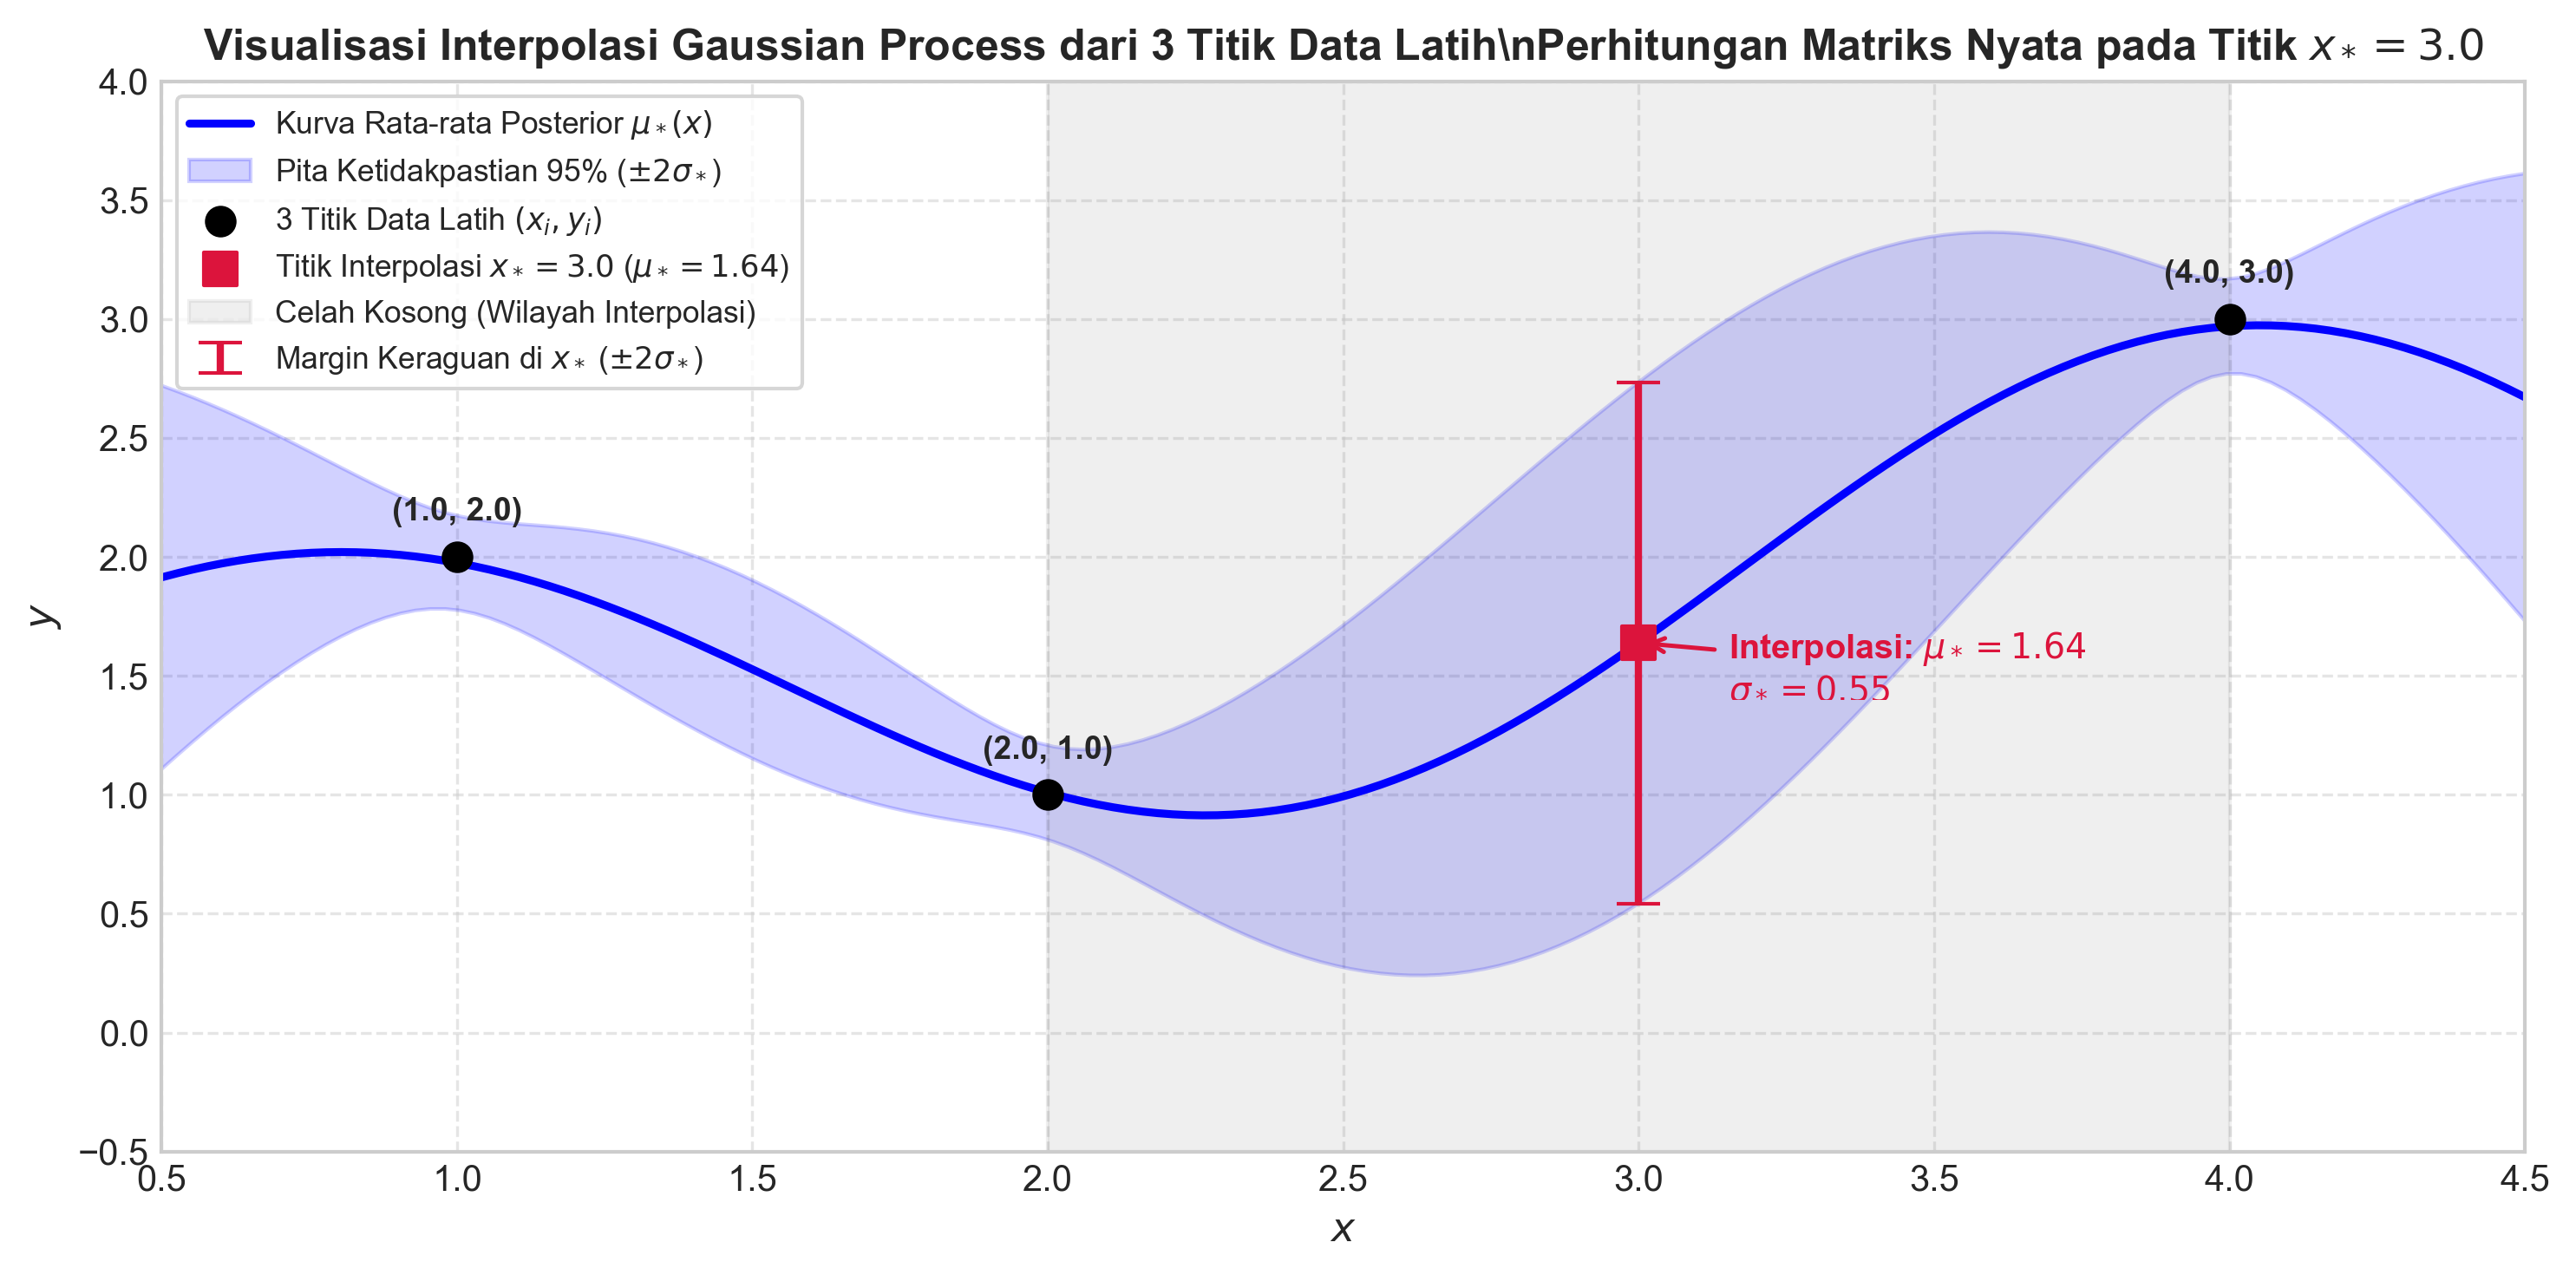

HASIL PERHITUNGAN MATRIKS DUMMY:
• Titik Interpolasi x*               : 3.0
• Vektor Kemiripan k*               : [0.1353 0.6065 0.6065]
• Vektor Bobot Dual alpha           : [ 2.5003 -0.9223  3.0664]
• Rata-rata Prediksi mu*(x*)        : 1.6388
• Variansi Prediksi sigma*²(x*)     : 0.3002
• Standar Deviasi sigma*(x*)        : 0.5479
• Interval 95% keyakinan            : [0.5430, 2.7347]


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup Data Dummy 3 Titik
X_tr = np.array([1.0, 2.0, 4.0])
y_tr = np.array([2.0, 1.0, 3.0])

l = 1.0
sigma_f = 1.0
sigma_n2 = 0.01

def kernel_rbf(x1, x2):
    return sigma_f**2 * np.exp(-0.5 * ((x1[:, None] - x2[None, :]) / l)**2)

# 2. Perhitungan Matriks Training
K = kernel_rbf(X_tr, X_tr)
Ky = K + sigma_n2 * np.eye(3)
Ky_inv = np.linalg.inv(Ky)
alpha = Ky_inv @ y_tr

# 3. Titik Interpolasi Spesifik x* = 3.0
x_star = np.array([3.0])
k_star = kernel_rbf(X_tr, x_star).flatten()
mu_star = k_star @ alpha
var_star = 1.0 - k_star @ Ky_inv @ k_star
std_star = np.sqrt(var_star)

# 4. Kurva Kontinu untuk Visualisasi
x_grid = np.linspace(0.0, 5.0, 200)
k_grid = kernel_rbf(X_tr, x_grid) # (3, 200)
mu_grid = k_grid.T @ alpha
var_grid = 1.0 - np.sum(k_grid * (Ky_inv @ k_grid), axis=0)
std_grid = np.sqrt(np.maximum(var_grid, 1e-6))

# Plotting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.figure(figsize=(10, 5), dpi=300)

# Plot kurva GP
plt.plot(x_grid, mu_grid, 'b-', lw=2.2, label=r'Kurva Rata-rata Posterior $\mu_*(x)$')
plt.fill_between(x_grid, mu_grid - 2*std_grid, mu_grid + 2*std_grid, color='blue', alpha=0.18, label=r'Pita Ketidakpastian 95% ($\pm 2\sigma_*$)')

# Plot 3 Titik Data Latih
plt.scatter(X_tr, y_tr, color='black', s=60, zorder=5, label='3 Titik Data Latih $(x_i, y_i)$')
for xi, yi in zip(X_tr, y_tr):
    plt.annotate(f'({xi:.1f}, {yi:.1f})', (xi, yi), textcoords="offset points", xytext=(0, 10), ha='center', fontweight='bold', fontsize=9)

# Highlight Titik Interpolasi x* = 3.0
plt.scatter(x_star, [mu_star], color='crimson', marker='s', s=80, zorder=6, label=f'Titik Interpolasi $x_*=3.0$ ($\\mu_*={mu_star:.2f}$)')
plt.errorbar(x_star, [mu_star], yerr=[2*std_star], fmt='none', ecolor='crimson', elinewidth=2, capsize=6, zorder=6, label=r'Margin Keraguan di $x_*$ ($\pm 2\sigma_*$)')
plt.annotate(f'Interpolasi: $\mu_*={mu_star:.2f}$\n$\sigma_*={std_star:.2f}$', (x_star[0], mu_star), textcoords="offset points", xytext=(25, -15), fontweight='bold', color='crimson', fontsize=9.5, arrowprops=dict(arrowstyle="->", color='crimson', lw=1.2))

# Highlight Celah
plt.axvspan(2.0, 4.0, color='gray', alpha=0.12, label='Celah Kosong (Wilayah Interpolasi)')

plt.title('Visualisasi Interpolasi Gaussian Process dari 3 Titik Data Latih\\nPerhitungan Matriks Nyata pada Titik $x_* = 3.0$', fontweight='bold', fontsize=12)
plt.xlabel('$x$', fontsize=11); plt.ylabel('$y$', fontsize=11)
plt.xlim(0.5, 4.5); plt.ylim(-0.5, 4.0)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', frameon=True, fontsize=8.5)
plt.tight_layout()
plt.show()

# Print Verifikasi Numerik
print("=" * 75)
print("HASIL PERHITUNGAN MATRIKS DUMMY:")
print("=" * 75)
print(f"• Titik Interpolasi x*               : {x_star[0]}")
print(f"• Vektor Kemiripan k*               : {k_star.round(4)}")
print(f"• Vektor Bobot Dual alpha           : {alpha.round(4)}")
print(f"• Rata-rata Prediksi mu*(x*)        : {mu_star:.4f}")
print(f"• Variansi Prediksi sigma*²(x*)     : {var_star:.4f}")
print(f"• Standar Deviasi sigma*(x*)        : {std_star:.4f}")
print(f"• Interval 95% keyakinan            : [{mu_star - 2*std_star:.4f}, {mu_star + 2*std_star:.4f}]")
print("=" * 75)



---
# 🔍 Evaluasi Titik Kisi (Dense Grid) dan Analisis Dimensi Matriks ($K_*$ dan $\boldsymbol{\alpha}$)

> **Pertanyaan Diskusi**:  
> 1. *"Apakah benar untuk mendapatkan pita yang halus seperti pada gambar, maka kita mengevaluasi titik yang banyak?"*  
> 2. *"Jika iya, apakah akan ada ketidakcocokan dimensi matriks $k_*$ dan $\alpha$?"*

---

## 📌 1. Pertanyaan 1: Mengapa Harus Mengevaluasi Banyak Titik untuk Mendapatkan Pita Halus?

### **Jawaban: YA, BENAR SEKALI.**

Secara matematis, Gaussian Process mendefinisikan distribusi probabilitas fungsi kontinu pada seluruh garis bilangan real $\mathbb{R}$ (tak terhingga titik). Namun, **komputer dan pustaka visualisasi (seperti Matplotlib) bekerja secara diskret**:
1. Komputer tidak dapat menggambar kurva kontinu murni secara langsung dari fungsi analitis abstrak. Komputer hanya bisa menghitung nilai pada sekumpulan titik diskret, lalu menghubungkan titik-titik tersebut dengan segmen garis lurus tipis antar piksel.
2. Untuk menghasilkan kurva rata-rata $\mu(x)$ dan pita ketidakpastian (confidence band $\pm 2\sigma(x)$) yang tampak **mulus tanpa patahan**, kita mendefinisikan sebuah **kisi uji yang sangat rapat (dense grid)**:
   $$X_* = \text{np.linspace}(x_{\min}, x_{\max}, M)$$
   di mana $M$ biasanya dipilih cukup besar, seperti $M = 200, 500,$ atau $1000$ titik.
3. Model GP kemudian mengevaluasi mean $\mu(x_{*j})$ dan standar deviasi $\sigma(x_{*j})$ pada **ke-$M$ titik kisi tersebut**.
4. Fungsi plotting seperti `plt.fill_between(x_grid, lower, upper)` mengisi area di antara batas bawah dan batas atas pada ke-$M$ titik tersebut. Karena jarak antar titik uji sangat rapat ($\Delta x = \frac{x_{\max} - x_{\min}}{M-1} \to 0$), mata manusia melihatnya sebagai **pita yang halus dan melengkung mulus**.
5. **Perbandingan Kontras**: Jika kita hanya mengevaluasi sedikit titik (misalnya hanya $M = 5$ titik), pita yang dihasilkan akan terlihat kasar, kaku, dan memiliki sudut-sudut patahan yang tajam (poligonal).

---

## 📐 2. Pertanyaan 2: Apakah Akan Ada Ketidakcocokan Dimensi Matriks $K_*$ dan $\boldsymbol{\alpha}$?

### **Jawaban: TIDAK ADA KETIDAKCOCOKAN SAMA SEKALI.**
Justru dalam kaidah aljabar linear, **dimensinya sangat harmonis dan cocok secara sempurna!**

Mari kita bedah secara formal aljabar matriksnya:

### A. Dimensi Vektor Bobot Latih ($\boldsymbol{\alpha}$)
Diberikan $N$ titik data latih (pada contoh dummy kita, $N = 3$ titik):
$$\boldsymbol{\alpha} = K_y^{-1} \mathbf{y}$$
* Matriks kovariansi data latih: $K_y = K(X, X) + \sigma_n^2 I \in \mathbb{R}^{N \times N} \quad (3 \times 3)$
* Inversnya: $K_y^{-1} \in \mathbb{R}^{N \times N} \quad (3 \times 3)$
* Vektor target observasi: $\mathbf{y} \in \mathbb{R}^{N \times 1} \quad (3 \times 1)$
* Vektor bobot dual:
  $$\boldsymbol{\alpha} = \underbrace{K_y^{-1}}_{[N \times N]} \times \underbrace{\mathbf{y}}_{[N \times 1]} = \underbrace{\boldsymbol{\alpha}}_{[N \times 1]} \quad (3 \times 1)$$

> ⚠️ **Prinsip Fundamental**:  
> Vektor $\boldsymbol{\alpha}$ **HANYA BERGANTUNG PADA DATA TRAINING ($N$)**.  
> Berapa pun jumlah titik uji baru yang ingin dievaluasi (apakah $1$ titik, $200$ titik, atau $1.000.000$ titik), **vektor $\boldsymbol{\alpha}$ TETAP BERDIMENSI $[N \times 1]$ ($3 \times 1$) dan TIDAK PERNAH BERUBAH UKURANNYA**.

---

### B. Transisi dari 1 Titik Uji ($M=1$) ke Banyak Titik Kisi ($M=200$)

#### Kasus 1: Evaluasi 1 Titik Uji Tunggal ($M = 1$, misal $x_* = 3.0$)
* Vektor kemiripan titik uji terhadap $N=3$ data latih:
  $$\mathbf{k}_* = \begin{bmatrix} k(x_*, x_1) & k(x_*, x_2) & k(x_*, x_3) \end{bmatrix} \in \mathbb{R}^{1 \times N} \quad (1 \times 3)$$
* Prediksi rata-rata:
  $$\mu_* = \mathbf{k}_* \boldsymbol{\alpha} \implies \underbrace{\mathbf{k}_*}_{[1 \times 3]} \times \underbrace{\boldsymbol{\alpha}}_{[3 \times 1]} = \underbrace{\mu_*}_{[1 \times 1]} \quad (\text{skalar tunggal})$$

#### Kasus 2: Evaluasi Banyak Titik Kisi Sekaligus ($M = 200$ titik)
Ketika kita mengevaluasi vektor kisi $X_* = [x_{*1}, x_{*2}, \dots, x_{*M}]^T \in \mathbb{R}^{M \times 1}$, notasi kemiripan berubah dari vektor baris tunggal $\mathbf{k}_*$ menjadi **Matriks Kovariansi Silang $K_*$**:
$$K_* = K(X_*, X_{\text{train}}) = \begin{bmatrix}
k(x_{*1}, x_1) & k(x_{*1}, x_2) & \cdots & k(x_{*1}, x_N) \\
k(x_{*2}, x_1) & k(x_{*2}, x_2) & \cdots & k(x_{*2}, x_N) \\
\vdots & \vdots & \ddots & \vdots \\
k(x_{*M}, x_1) & k(x_{*M}, x_2) & \cdots & k(x_{*M}, x_N)
\end{bmatrix} \in \mathbb{R}^{M \times N} \quad (200 \times 3)$$

Perhatikan struktur matriks $K_*$:
* **Jumlah baris = $M$ ($200$)**: Masing-masing baris mewakili 1 titik uji di kisi visualisasi.
* **Jumlah kolom = $N$ ($3$)**: Mewakili kemiripan titik uji tersebut ke masing-masing $N$ titik data latih.

---

### C. Perkalian Matriks Prediksi Rata-rata ($\boldsymbol{\mu}_*$)

Syarat perkalian dua matriks: **Jumlah kolom matriks pertama harus sama dengan jumlah baris matriks kedua**.
$$\boldsymbol{\mu}_* = K_* \cdot \boldsymbol{\alpha}$$
Tinjau dimensinya:
$$\underbrace{K_*}_{[M \times N]} \times \underbrace{\boldsymbol{\alpha}}_{[N \times 1]} = \underbrace{\boldsymbol{\mu}_*}_{[M \times 1]}$$
Substitusikan ukuran konkret kita ($M = 200, N = 3$):
$$\underbrace{K_*}_{[200 \times 3]} \times \underbrace{\boldsymbol{\alpha}}_{[3 \times 1]} = \underbrace{\boldsymbol{\mu}_*}_{[200 \times 1]}$$

* Kolom $K_*$ = $3$
* Baris $\boldsymbol{\alpha}$ = $3$
* **Sangat cocok! Tidak ada ketidakcocokan dimensi.**
* Hasilnya adalah sebuah vektor $\boldsymbol{\mu}_* \in \mathbb{R}^{M \times 1}$ ($200 \times 1$) yang berisi nilai rata-rata prediksi untuk seluruh $200$ titik kisi!

---

### D. Perhitungan Variansi dan Pita Ketidakpastian ($\boldsymbol{\sigma}_*^2$)

Matriks kovariansi posterior lengkap untuk seluruh $M$ titik adalah:
$$\Sigma_* = K(X_*, X_*) - K_* K_y^{-1} K_*^T \in \mathbb{R}^{M \times M} \quad (200 \times 200)$$
Periksa dimensi suku kedua:
$$\underbrace{K_*}_{[M \times N]} \times \underbrace{K_y^{-1}}_{[N \times N]} \times \underbrace{K_*^T}_{[N \times M]} = \underbrace{[M \times M]}_{[200 \times 200]}$$
Semua dimensi perkalian matriks cocok sempurna!

Untuk membuat pita bayangan pada grafik 2D, kita tidak memerlukan seluruh matriks kovariansi antar titik uji ($200 \times 200$), melainkan **hanya variansi marginal pada masing-masing titik uji**, yaitu **elemen diagonal utama**:
$$\boldsymbol{\sigma}_*^2 = \text{diag}(\Sigma_*) \in \mathbb{R}^{M \times 1} \quad (200 \times 1)$$
Deviasi standar untuk setiap titik:
$$\boldsymbol{\sigma}_* = \sqrt{\boldsymbol{\sigma}_*^2} \in \mathbb{R}^{M \times 1} \quad (200 \times 1)$$

Batas atas dan batas bawah pita keyakinan $95\%$ ($\pm 2\sigma$):
$$\text{upper} = \boldsymbol{\mu}_* + 2\boldsymbol{\sigma}_* \in \mathbb{R}^{M \times 1} \quad (200 \times 1)$$
$$\text{lower} = \boldsymbol{\mu}_* - 2\boldsymbol{\sigma}_* \in \mathbb{R}^{M \times 1} \quad (200 \times 1)$$

Karena vektor `x_grid`, `lower`, dan `upper` **ketiganya berukuran persis sama: $[200 \times 1]$**, fungsi `plt.fill_between(x_grid, lower, upper)` mengeksekusinya tanpa masalah dimensi!

---

### 📊 Ringkasan Dimensi Matriks

| Komponen | Notasi | Dimensi (1 Titik Uji, $M=1$) | Dimensi (Kisi Rapat, $M=200$) | Keterangan |
| :--- | :---: | :---: | :---: | :--- |
| **Data Latih** | $X_{\text{train}}$ | $N \times 1 = 3 \times 1$ | $N \times 1 = 3 \times 1$ | Tetap |
| **Target Latih** | $\mathbf{y}$ | $N \times 1 = 3 \times 1$ | $N \times 1 = 3 \times 1$ | Tetap |
| **Bobot Dual** | $\boldsymbol{\alpha}$ | $N \times 1 = 3 \times 1$ | $N \times 1 = 3 \times 1$ | **Selalu tetap berukuran $N \times 1$** |
| **Titik Evaluasi** | $X_*$ | $1 \times 1$ | $M \times 1 = 200 \times 1$ | Jumlah titik diperbanyak |
| **Kernel Silang** | $K_*$ | $1 \times N = 1 \times 3$ | $M \times N = 200 \times 3$ | Baris membesar seiring jumlah titik uji |
| **Prediksi Mean** | $\boldsymbol{\mu}_* = K_* \boldsymbol{\alpha}$ | $[1 \times 3] \times [3 \times 1] = \mathbf{[1 \times 1]}$ | $[200 \times 3] \times [3 \times 1] = \mathbf{[200 \times 1]}$ | **Cocok sempurna!** |
| **Variansi Pita** | $\boldsymbol{\sigma}_*^2$ | $[1 \times 1]$ | $[200 \times 1]$ | Diagonal utama kovariansi |


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Menggunakan parameter dan data dummy 3 titik sebelumnya
X_tr = np.array([1.0, 2.0, 4.0])
y_tr = np.array([2.0, 1.0, 3.0])
N = len(X_tr)

l = 1.0
sigma_f = 1.0
sigma_n2 = 0.01

def kernel_rbf(x1, x2):
    return sigma_f**2 * np.exp(-0.5 * ((x1[:, None] - x2[None, :]) / l)**2)

# Training: Bobot dual alpha (dimensi N x 1 = 3 x 1)
Ky = kernel_rbf(X_tr, X_tr) + sigma_n2 * np.eye(N)
Ky_inv = np.linalg.inv(Ky)
alpha = Ky_inv @ y_tr # shape: (3,)

# 2. Eksperimen: Evaluasi M = 5 titik (Kasar) vs M = 200 titik (Halus)
M_coarse = 5
M_dense = 200

x_coarse = np.linspace(0.5, 4.5, M_coarse)
x_dense = np.linspace(0.5, 4.5, M_dense)

# A. Evaluasi pada M = 5 titik
K_star_coarse = kernel_rbf(x_coarse, X_tr) # shape: (5, 3)
mu_coarse = K_star_coarse @ alpha           # (5, 3) @ (3,) -> shape: (5,)
var_coarse = 1.0 - np.sum(K_star_coarse * (K_star_coarse @ Ky_inv), axis=1)
std_coarse = np.sqrt(np.maximum(var_coarse, 1e-6))

# B. Evaluasi pada M = 200 titik
K_star_dense = kernel_rbf(x_dense, X_tr)   # shape: (200, 3)
mu_dense = K_star_dense @ alpha             # (200, 3) @ (3,) -> shape: (200,)
var_dense = 1.0 - np.sum(K_star_dense * (K_star_dense @ Ky_inv), axis=1)
std_dense = np.sqrt(np.maximum(var_dense, 1e-6))

# 3. Visualisasi Perbandingan
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=300, sharey=True)

# Subplot 1: M = 5 titik (Kasar / Patah-patah)
ax1 = axes[0]
ax1.plot(x_coarse, mu_coarse, 'o-', color='darkorange', lw=2, label=r'Mean $\mu_*(x)$ ($M=5$ titik)')
ax1.fill_between(x_coarse, mu_coarse - 2*std_coarse, mu_coarse + 2*std_coarse, 
                 color='orange', alpha=0.3, label=r'Pita Ketidakpastian Kasar ($\pm 2\sigma_*)')
ax1.scatter(X_tr, y_tr, color='black', s=70, zorder=5, label='Data Latih ($N=3$)')
ax1.set_title(f'Evaluasi Sedikit Titik ($M = {M_coarse}$)\nPita Kasar & Berpatah-patah', fontweight='bold', fontsize=11)
ax1.set_xlabel('$x$'); ax1.set_ylabel('$y$')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left', fontsize=8.5)

# Subplot 2: M = 200 titik (Halus / Kontinu)
ax2 = axes[1]
ax2.plot(x_dense, mu_dense, '-', color='navy', lw=2.2, label=r'Mean $\mu_*(x)$ ($M=200$ titik)')
ax2.fill_between(x_dense, mu_dense - 2*std_dense, mu_dense + 2*std_dense, 
                 color='blue', alpha=0.2, label=r'Pita Ketidakpastian Halus ($\pm 2\sigma_*)')
ax2.scatter(X_tr, y_tr, color='black', s=70, zorder=5, label='Data Latih ($N=3$)')
ax2.set_title(f'Evaluasi Kisi Rapat ($M = {M_dense}$)\nPita Halus & Mulus', fontweight='bold', fontsize=11)
ax2.set_xlabel('$x$')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left', fontsize=8.5)

plt.tight_layout()
plt.show()

# 4. Verifikasi Konsistensi Dimensi Matriks
print("=" * 70)
print("VERIFIKASI DIMENSI MATRIKS (ALJABAR LINEAR):")
print("=" * 70)
print(f"• Jumlah Data Latih (N)             : {N}")
print(f"• Shape Vektor Bobot Dual (alpha)   : {alpha.shape}  [N = {N}]")
print(f"• Jumlah Titik Uji Rapat (M)        : {M_dense}")
print(f"• Shape Matriks Kernel Silang (K_*) : {K_star_dense.shape}  [M x N = {M_dense} x {N}]")
print(f"• Perkalian (K_* @ alpha) -> mu_*   : {mu_dense.shape}  [M = {M_dense}]")
print(f"• Shape Standar Deviasi (sigma_*)   : {std_dense.shape}  [M = {M_dense}]")
print("-" * 70)
print("KESIMPULAN: Dimensi kolom K_* (3) persis sama dengan baris alpha (3).")
print("Hasil prediksi mean dan pita variansi berukuran (200,), cocok sempurna!")
print("=" * 70)
